# Predicción del abandono de clientes

Usamos el conjunto Iranian Churn para predecir si un cliente de telecomunicaciones abandona el servicio. La variable objetivo es abandono: 1 si abandonó y 0 si permaneció.

El cuaderno sigue las etapas de un proyecto de analítica, del entendimiento del negocio al despliegue. Cada herramienta se importa y se explica en la etapa donde se usa.

<a id="indice"></a>
## Índice

1. [Entendimiento del negocio](#seccion-1)
2. [Enfoque analítico](#seccion-2)
3. [Requerimiento de datos](#seccion-3)
4. [Recolección de los datos](#seccion-4)
5. [Separación de entrenamiento y prueba](#seccion-5)
6. [Entendimiento de los datos](#seccion-6)
7. [Preparación de los datos](#seccion-7)
8. [Modelado](#seccion-8)
9. [Ajuste de hiperparámetros](#seccion-9)
10. [Calibración y umbral](#seccion-10)
11. [Evaluación final](#seccion-11)
12. [Despliegue y conclusiones](#seccion-12)

<a id="seccion-1"></a>
## 1. Entendimiento del negocio

Una empresa de telecomunicaciones en Irán pierde clientes que se van a la competencia. Conseguir un cliente nuevo cuesta bastante más que retener a uno que ya se tiene, así que a la empresa le interesa saber quién está a punto de irse para contactarlo antes.

El equipo de retención no puede llamar a todos los clientes: tiene capacidad para atender a unos pocos cada mes. Lo que necesita es una lista corta de clientes en riesgo, ordenada por prioridad.

Dos errores cuestan distinto. Dejar escapar a un cliente que sí se iba significa perderlo; llamar a uno que no pensaba irse solo gasta una llamada. Por eso nos importa más no dejar escapar clientes que acertar en todas las llamadas.

[Volver al índice](#indice)

<a id="seccion-2"></a>
## 2. Enfoque analítico

El problema se plantea como una clasificación binaria: para cada cliente predecimos si abandona (1) o permanece (0).

La métrica principal es el F1 de la clase abandono, que combina dos cosas: cuántos de los clientes que se van alcanzamos a detectar y cuántas de nuestras alertas eran correctas. Miramos también la precisión y el recall por separado para entender cómo se reparte ese resultado.

No usamos la exactitud para decidir. Como la mayoría de los clientes permanece, un modelo que respondiera siempre permanece acertaría la mayor parte de las veces sin detectar a nadie en riesgo, que es justo lo que necesitamos.

El modelo además debe entregar una probabilidad por cliente, no solo una respuesta de sí o no, para poder ordenar la lista de contactos por prioridad.

[Volver al índice](#indice)

<a id="seccion-3"></a>
## 3. Requerimiento de datos

Para anticipar el abandono necesitamos información de cada cliente anterior al momento en que se va: cuánto usa el servicio, si ha tenido problemas, qué plan tiene y cuánto lleva contratado.

Usamos el conjunto Iranian Churn del repositorio UCI (https://archive.ics.uci.edu/dataset/563/iranian+churn+dataset), que recoge datos reales de una empresa de telecomunicaciones iraní. Las variables de entrada corresponden a los primeros nueve meses y el abandono se registra al terminar el mes doce, así que las entradas son anteriores al desenlace que queremos predecir.

Dos cosas que harían falta y el archivo no trae: un identificador de cliente y las fechas de cada medición. Sin identificador no podemos saber si dos filas iguales son el mismo cliente, y sin fechas no podemos comprobar el orden de los hechos cliente por cliente. Lo tenemos en cuenta al interpretar los resultados.

[Volver al índice](#indice)

<a id="seccion-4"></a>
## 4. Recolección de los datos

Cargamos el archivo original, revisamos qué trae y dejamos los nombres de las columnas en español. El archivo no se modifica en ningún momento.

### 4.1. Ruta de los datos

En local el cuaderno se ejecuta desde la carpeta del proyecto. Para Colab hay que activar EN_COLAB y ajustar la ruta en Drive.

In [1]:
EN_COLAB = False

if EN_COLAB:
    %pip install phik imbalanced-learn -q
    from google.colab import drive
    drive.mount("/content/drive")
    RUTA_BASE = "/content/drive/MyDrive/churn/"
else:
    RUTA_BASE = "./"

RUTA_DATOS = RUTA_BASE + "data/"
ruta_original = RUTA_DATOS + "original/Customer Churn.csv"


### 4.2. Carga del archivo

pandas es la librería con la que trabajamos las tablas.

In [2]:
import pandas as pd


In [3]:
datos_originales = pd.read_csv(ruta_original)
datos_originales.head()


,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


### 4.3. Tamaño de la tabla

In [4]:
print("Filas:", datos_originales.shape[0])
print("Columnas:", datos_originales.shape[1])


Filas: 3150
Columnas: 14


3.150 filas y 14 columnas. Churn es la variable objetivo.

### 4.4. Tipos de datos y valores faltantes

In [5]:
revision_columnas = pd.DataFrame({
    "Tipo": datos_originales.dtypes.astype(str),
    "Valores faltantes": datos_originales.isna().sum()
})
revision_columnas


,Tipo,Valores faltantes
Call Failure,int64,0
Complains,int64,0
Subscription Length,int64,0
Charge Amount,int64,0
Seconds of Use,int64,0
Frequency of use,int64,0
Frequency of SMS,int64,0
Distinct Called Numbers,int64,0
Age Group,int64,0
Tariff Plan,int64,0


No hay valores faltantes. Todas las columnas son numéricas, pero algunas representan categorías, como las quejas o el plan tarifario.

### 4.5. Filas repetidas

In [6]:
filas_repetidas = datos_originales.duplicated().sum()
print("Filas repetidas:", filas_repetidas)


Filas repetidas: 300


Hay 300 filas repetidas. Las conservamos: sin identificador de cliente no se puede afirmar que sean el mismo cliente registrado dos veces, así que tratamos cada fila como un cliente distinto.

### 4.6. Nombres de las columnas

Trabajamos sobre una copia de la tabla original.

In [7]:
nombres = {
    "Call  Failure": "fallas_llamadas",
    "Complains": "quejas",
    "Subscription  Length": "antiguedad",
    "Charge  Amount": "nivel_cargo",
    "Seconds of Use": "segundos_uso",
    "Frequency of use": "frecuencia_uso",
    "Frequency of SMS": "frecuencia_sms",
    "Distinct Called Numbers": "numeros_distintos",
    "Age Group": "grupo_edad",
    "Tariff Plan": "plan_tarifario",
    "Status": "estado",
    "Age": "edad",
    "Customer Value": "valor_cliente",
    "Churn": "abandono"
}

datos = datos_originales.rename(columns=nombres).copy()

datos.head()


,fallas_llamadas,quejas,antiguedad,nivel_cargo,segundos_uso,frecuencia_uso,frecuencia_sms,numeros_distintos,grupo_edad,plan_tarifario,estado,edad,valor_cliente,abandono
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


### 4.7. Estado y valor del cliente

Conservamos estado y valor_cliente como entradas.

estado vale 1 si el cliente está activo y 2 si no lo está, así que es una categoría. valor_cliente es un valor calculado cuya fórmula UCI no publica, por lo que no lo leemos como dinero. Por esa falta de documentación las revisamos aparte en la sección 6, ya con los datos de entrenamiento separados.

In [8]:
datos[["estado", "valor_cliente"]].head()


,estado,valor_cliente
0,1,197.640
1,2,46.035
2,1,1536.520
3,1,240.020
4,1,145.805


Quedan 3.150 filas con 13 entradas más abandono. No hubo que completar ni eliminar nada.

[Volver al índice](#indice)

<a id="seccion-5"></a>
## 5. Separación de entrenamiento y prueba

Separamos los datos antes de mirarlos a fondo. Si exploráramos la tabla completa, las decisiones que tomemos después estarían influidas por los clientes que después usamos para evaluar, y el resultado final se vería mejor de lo que es.

Dividimos en 80 % para entrenamiento y 20 % para prueba, con partición estratificada para que las dos partes conserven la proporción de abandono y random_state=42 para poder repetirla.

La prueba queda reservada desde aquí: no se usa para explorar, comparar ni ajustar, solo para la evaluación final de la sección 11.

Cada fila es un cliente distinto, porque el archivo no trae identificador, así que repartimos las filas sin agrupar perfiles idénticos.

La función que parte los datos viene de scikit-learn.

In [9]:
from sklearn.model_selection import train_test_split


### 5.1. Variables de entrada y variable objetivo

In [10]:
X = datos.drop(columns="abandono")
y = datos["abandono"]

print("Variables de entrada:", X.shape[1])
print("Filas:", len(X))
print("Permanencias (0):", int((y == 0).sum()))
print("Abandonos (1):", int((y == 1).sum()))
print("Porcentaje de abandono:", round((y == 1).mean() * 100, 2))


Variables de entrada: 13
Filas: 3150
Permanencias (0): 2655
Abandonos (1): 495
Porcentaje de abandono: 15.71


Hay 3.150 filas: 2.655 de permanencia y 495 de abandono, un 15,71 %. Por cada cliente que abandona hay más de cinco que permanecen, y ese desbalance es la razón de usar el F1 del abandono como métrica principal.

### 5.2. Partición 80/20

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Filas de entrenamiento:", len(X_train))
print("Filas de prueba:", len(X_test))


Filas de entrenamiento: 2520
Filas de prueba: 630


2.520 filas de entrenamiento y 630 de prueba.

### 5.3. Verificación de la estratificación

Si la partición quedó bien hecha, los tres porcentajes de abandono deben ser casi iguales.

In [12]:
rows = []

for nombre_conjunto, serie in [("Completo", y), ("Entrenamiento", y_train), ("Prueba", y_test)]:
    rows.append({
        "Conjunto": nombre_conjunto,
        "Filas": len(serie),
        "Permanencia (0)": int((serie == 0).sum()),
        "Abandono (1)": int((serie == 1).sum()),
        "% Abandono": round((serie == 1).mean() * 100, 2)
    })

tabla_particion = pd.DataFrame(rows)
tabla_particion


,Conjunto,Filas,Permanencia (0),Abandono (1),% Abandono
0,Completo,3150,2655,495,15.71
1,Entrenamiento,2520,2124,396,15.71
2,Prueba,630,531,99,15.71


Los tres coinciden en 15,71 %: 396 abandonos en entrenamiento y 99 en prueba.

### 5.4. Tablas de entrenamiento y prueba

Armamos train y test con sus entradas y su columna abandono, y reiniciamos el índice.

In [13]:
train = pd.concat([X_train, y_train], axis=1).reset_index(drop=True)
test = pd.concat([X_test, y_test], axis=1).reset_index(drop=True)

X_train = train.drop(columns="abandono")
y_train = train["abandono"]
X_test = test.drop(columns="abandono")
y_test = test["abandono"]

print("Tabla de entrenamiento:", train.shape)
print("Tabla de prueba:", test.shape)

train.head()


Tabla de entrenamiento: (2520, 14)
Tabla de prueba: (630, 14)


,fallas_llamadas,quejas,antiguedad,nivel_cargo,segundos_uso,frecuencia_uso,frecuencia_sms,numeros_distintos,grupo_edad,plan_tarifario,estado,edad,valor_cliente,abandono
0,0,0,31,0,2420,10,0,8,3,1,1,30,97.200,0
1,15,0,40,1,4503,72,8,37,1,1,1,15,295.625,0
2,22,0,35,8,10840,98,2,40,4,1,1,45,278.450,0
3,0,0,33,0,795,12,0,7,2,1,2,25,36.315,0
4,1,0,34,0,7328,119,373,38,2,1,1,25,2013.615,0


train tiene 2.520 filas y test 630, las dos con 14 columnas. De aquí en adelante trabajamos solo con train, y la prueba no se vuelve a tocar hasta la sección 11.

[Volver al índice](#indice)

<a id="seccion-6"></a>
## 6. Entendimiento de los datos

Con el entrenamiento ya separado, miramos el desbalance, la distribución de cada variable, su asociación con el abandono y si hay variables que repiten la misma información.

matplotlib y seaborn para las gráficas, y phik para medir la asociación entre variables.

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import phik


### 6.1. Resumen de las variables

In [15]:
rows = []

for columna in train.columns:
    serie = train[columna]
    rows.append({
        "Variable": columna,
        "Tipo": str(serie.dtype),
        "Valores distintos": serie.nunique(),
        "Mínimo": serie.min(),
        "Máximo": serie.max(),
        "Promedio": round(serie.mean(), 2)
    })

tabla_variables = pd.DataFrame(rows)
tabla_variables


,Variable,Tipo,Valores distintos,Mínimo,Máximo,Promedio
0,fallas_llamadas,int64,37,0.0,36.00,7.64
1,quejas,int64,2,0.0,1.00,0.08
2,antiguedad,int64,45,3.0,47.00,32.59
3,nivel_cargo,int64,11,0.0,10.00,0.95
4,segundos_uso,int64,1528,0.0,16980.00,4453.48
5,frecuencia_uso,int64,238,0.0,254.00,69.39
6,frecuencia_sms,int64,382,0.0,522.00,73.75
7,numeros_distintos,int64,92,0.0,97.00,23.55
8,grupo_edad,int64,5,1.0,5.00,2.83
9,plan_tarifario,int64,2,1.0,2.00,1.08


La tabla tiene 14 columnas: 13 entradas y abandono. quejas, plan_tarifario y estado toman dos valores, grupo_edad cinco y nivel_cargo once.

edad también toma solo cinco valores (15, 25, 30, 45 y 55), los mismos niveles de grupo_edad. Lo revisamos en 4.7.

### 6.2. Desbalance de la variable objetivo

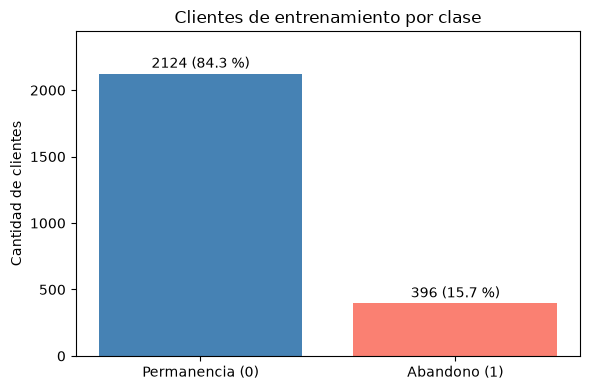

In [16]:
conteo = y_train.value_counts().reindex([0, 1], fill_value=0)
porcentajes = (conteo / len(y_train)) * 100

fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(["Permanencia (0)", "Abandono (1)"], conteo, color=["steelblue", "salmon"])
ax.set_title("Clientes de entrenamiento por clase")
ax.set_ylabel("Cantidad de clientes")
ax.set_ylim(0, conteo.max() * 1.15)

for barra, porcentaje in zip(barras, porcentajes):
    altura = barra.get_height()
    ax.text(barra.get_x() + barra.get_width() / 2, altura + 20,
            str(int(altura)) + " (" + str(round(porcentaje, 1)) + " %)",
            ha="center", va="bottom")

plt.tight_layout()
plt.show()


2.124 clientes permanecieron y 396 abandonaron, un 15,7 %. Un modelo que respondiera siempre permanece acertaría el 84,3 % de las veces sin detectar a nadie en riesgo, y por eso la exactitud no nos sirve para decidir.

### 6.3. Variables categóricas

Cinco variables son categorías: quejas, plan_tarifario, estado, nivel_cargo y grupo_edad. Para cada una contamos los clientes y su porcentaje de abandono.

In [17]:
columnas_categoricas = ["quejas", "plan_tarifario", "estado", "nivel_cargo", "grupo_edad"]

rows = []

for columna in columnas_categoricas:
    resumen = train.groupby(columna)["abandono"].agg(["count", "sum"])
    for categoria in resumen.index:
        clientes = int(resumen.loc[categoria, "count"])
        abandonos = int(resumen.loc[categoria, "sum"])
        rows.append({
            "Variable": columna,
            "Categoría": categoria,
            "Clientes": clientes,
            "Abandonos": abandonos,
            "% Abandono": round(abandonos / clientes * 100, 2)
        })

tabla_categoricas = pd.DataFrame(rows)
tabla_categoricas


,Variable,Categoría,Clientes,Abandonos,% Abandono
0,quejas,0,2318,233,10.05
1,quejas,1,202,163,80.69
2,plan_tarifario,1,2323,390,16.79
3,plan_tarifario,2,197,6,3.05
4,estado,1,1896,100,5.27
5,estado,2,624,296,47.44
6,nivel_cargo,0,1397,336,24.05
7,nivel_cargo,1,510,35,6.86
8,nivel_cargo,2,316,17,5.38
9,nivel_cargo,3,162,7,4.32


La misma información en gráficas.

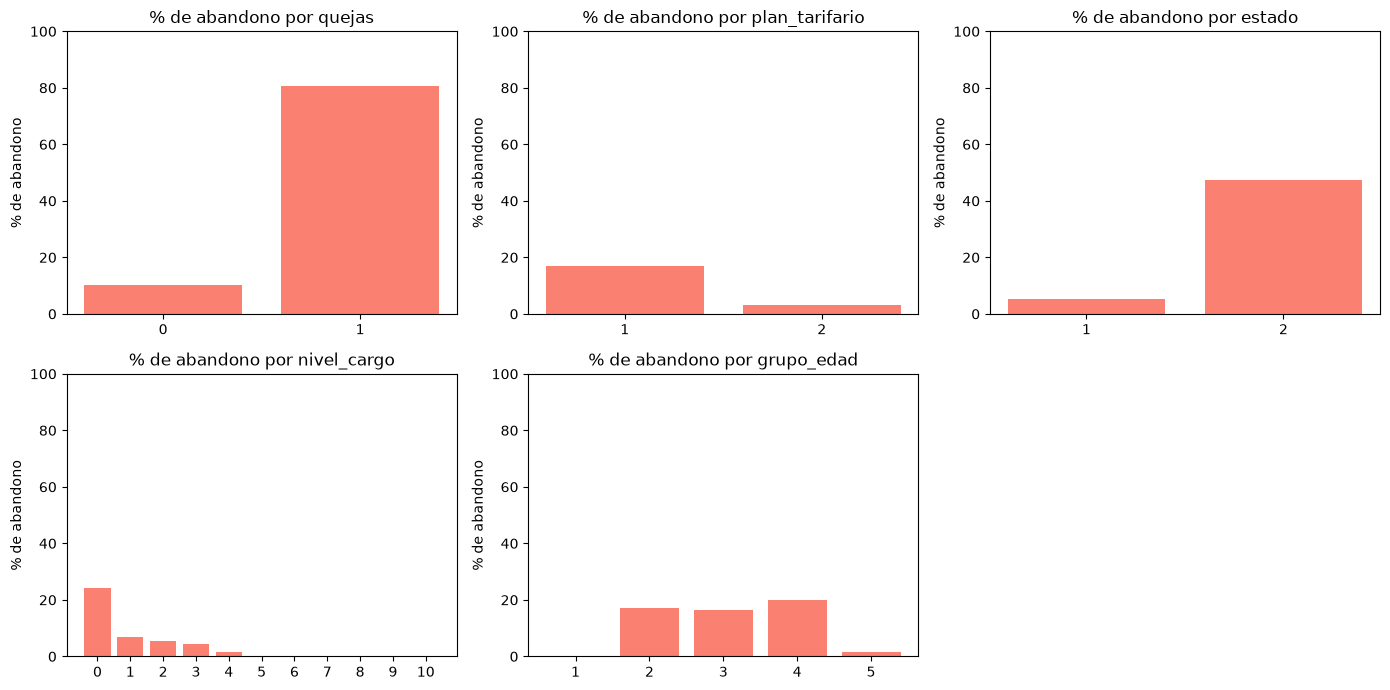

In [18]:
fig, ejes = plt.subplots(2, 3, figsize=(14, 7))
ejes = ejes.flatten()

for i, columna in enumerate(columnas_categoricas):
    datos_columna = tabla_categoricas[tabla_categoricas["Variable"] == columna]
    ejes[i].bar(datos_columna["Categoría"].astype(str), datos_columna["% Abandono"], color="salmon")
    ejes[i].set_title("% de abandono por " + columna)
    ejes[i].set_ylabel("% de abandono")
    ejes[i].set_ylim(0, 100)

for i in range(len(columnas_categoricas), len(ejes)):
    ejes[i].axis("off")

plt.tight_layout()
plt.show()


Dos variables separan los grupos con claridad: abandona el 80,69 % de los 202 clientes con queja, frente al 10,05 % del resto, y el 47,44 % de los 624 clientes no activos, frente al 5,27 % de los activos.

Las demás aportan menos. El plan contractual abandona un 3,05 % frente al 16,79 % del prepago. En nivel_cargo el abandono baja al subir el nivel y de 5 en adelante no hay ninguno, pero esos niveles tienen entre 6 y 24 clientes. En grupo_edad los grupos 1 y 5 casi no registran abandono, mientras que 2, 3 y 4 rondan el 17 %.

### 6.4. Variables numéricas

Las ocho restantes son cantidades. Revisamos su resumen y sus histogramas.

In [19]:
columnas_numericas = []

for columna in X_train.columns:
    if columna not in columnas_categoricas:
        columnas_numericas.append(columna)

print("Variables numéricas:", len(columnas_numericas))

train[columnas_numericas].describe().round(2)


Variables numéricas: 8


,fallas_llamadas,antiguedad,segundos_uso,frecuencia_uso,frecuencia_sms,numeros_distintos,edad,valor_cliente
count,2520.00,2520.00,2520.00,2520.00,2520.00,2520.00,2520.00,2520.00
mean,7.64,32.59,4453.48,69.39,73.75,23.55,31.01,472.65
std,7.27,8.57,4183.98,57.45,112.32,17.34,8.85,519.11
min,0.00,3.00,0.00,0.00,0.00,0.00,15.00,0.00
25%,1.00,30.00,1415.00,27.00,6.00,10.00,25.00,113.60
50%,6.00,35.00,2990.00,54.00,21.00,21.00,30.00,228.65
75%,11.00,38.00,6480.00,94.00,91.25,34.00,30.00,796.08
max,36.00,47.00,16980.00,254.00,522.00,97.00,55.00,2165.28


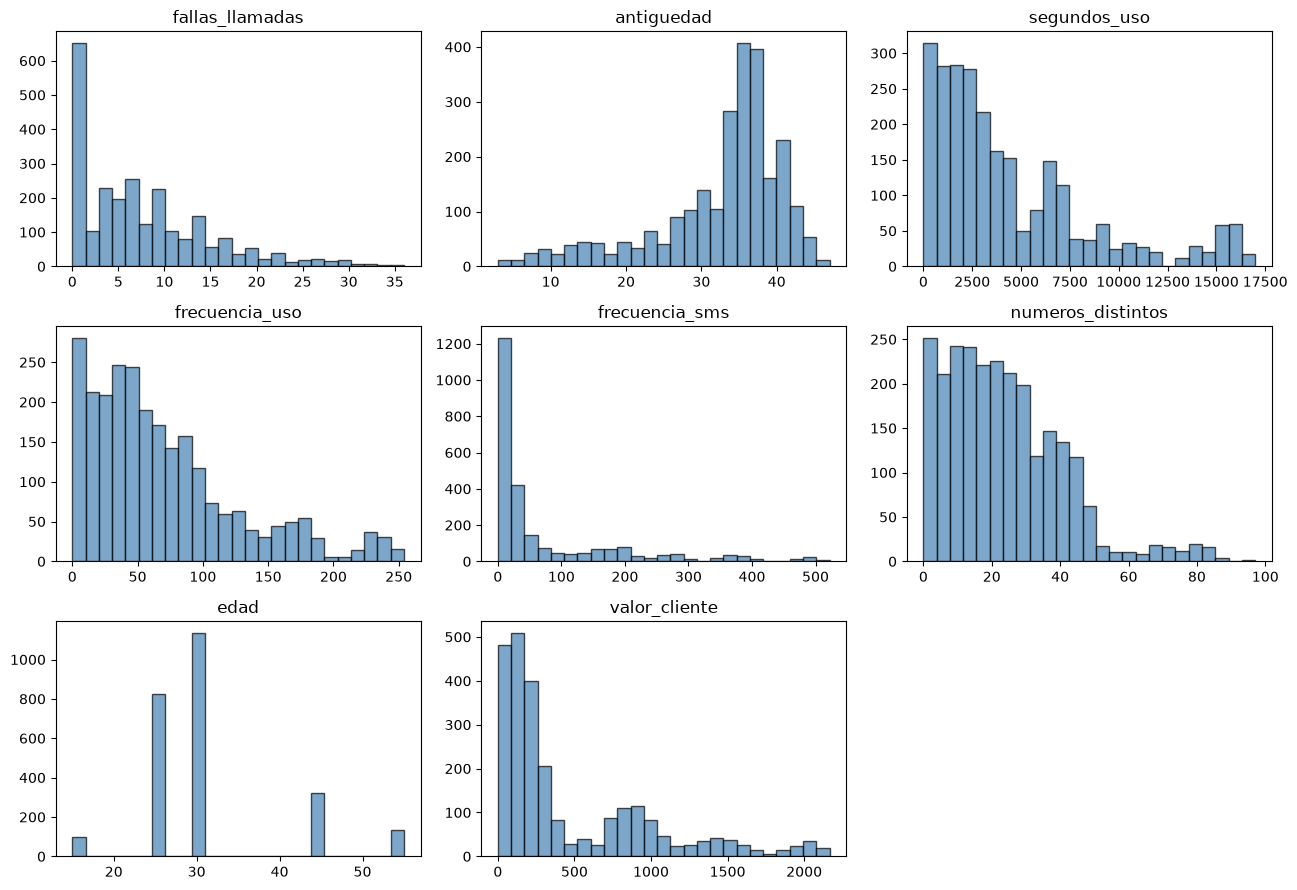

In [20]:
fig, ejes = plt.subplots(3, 3, figsize=(13, 9))
ejes = ejes.flatten()

for i, columna in enumerate(columnas_numericas):
    ejes[i].hist(train[columna], bins=25, color="steelblue", edgecolor="black", alpha=0.7)
    ejes[i].set_title(columna)

for i in range(len(columnas_numericas), len(ejes)):
    ejes[i].axis("off")

plt.tight_layout()
plt.show()


Las ocho tienen la media por encima de la mediana, señal de una cola larga a la derecha: segundos_uso promedia 4.453 con mediana 2.990 y valor_cliente 472,65 con mediana 228,65.

Las escalas son muy distintas entre sí, desde antiguedad entre 3 y 47 hasta segundos_uso que llega a 16.980, así que el escalado importa.

### 6.5. Diferencias entre quienes abandonan y quienes permanecen

Comparamos cada variable numérica entre los dos grupos, con diagramas de caja y con una tabla de medianas.

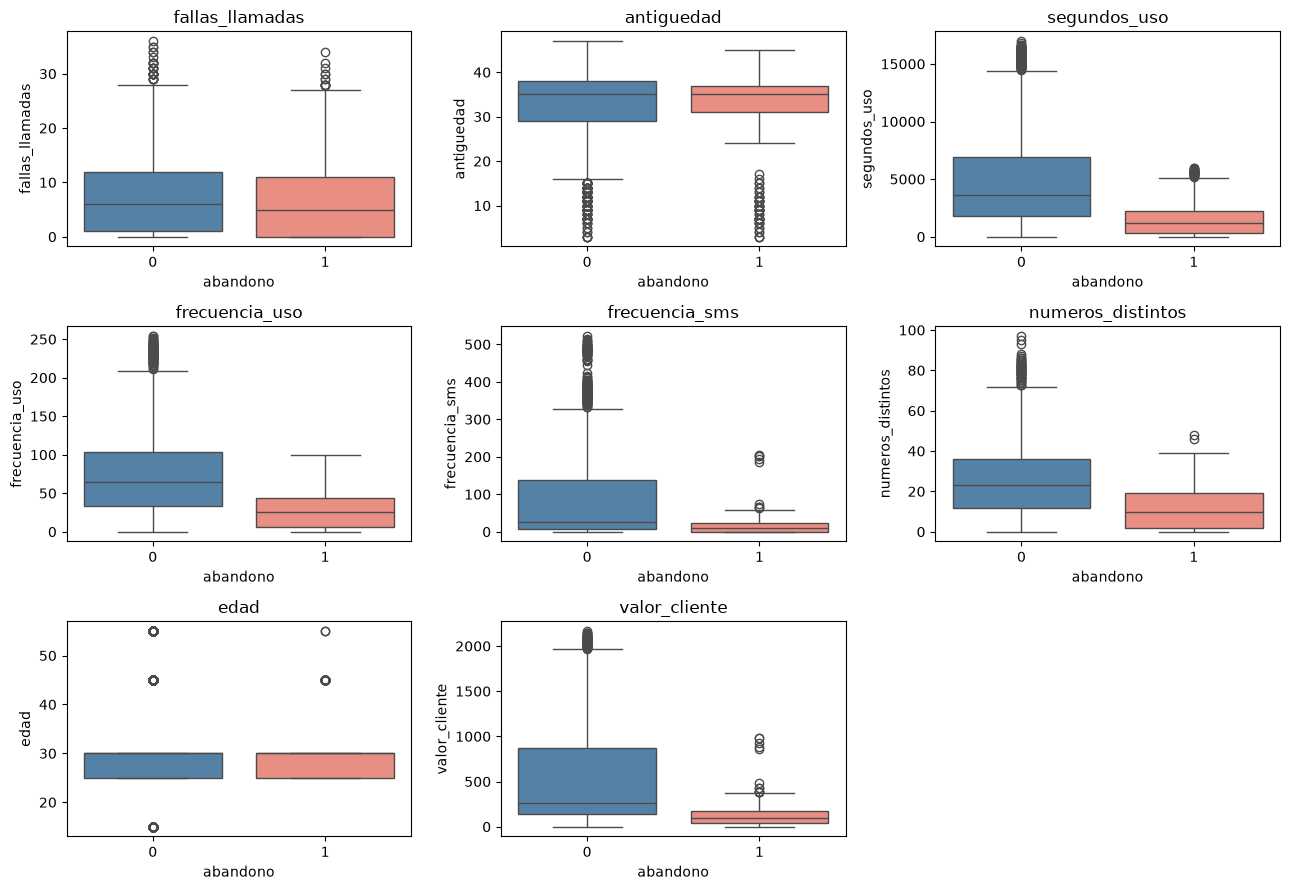

In [21]:
fig, ejes = plt.subplots(3, 3, figsize=(13, 9))
ejes = ejes.flatten()

for i, columna in enumerate(columnas_numericas):
    sns.boxplot(
        data=train, x="abandono", y=columna, hue="abandono",
        palette=["steelblue", "salmon"], legend=False, ax=ejes[i]
    )
    ejes[i].set_title(columna)

for i in range(len(columnas_numericas), len(ejes)):
    ejes[i].axis("off")

plt.tight_layout()
plt.show()


In [22]:
rows = []

for columna in columnas_numericas:
    mediana_permanencia = train.loc[train["abandono"] == 0, columna].median()
    mediana_abandono = train.loc[train["abandono"] == 1, columna].median()
    rows.append({
        "Variable": columna,
        "Mediana permanencia": round(mediana_permanencia, 2),
        "Mediana abandono": round(mediana_abandono, 2),
        "Diferencia": round(mediana_abandono - mediana_permanencia, 2)
    })

tabla_medianas = pd.DataFrame(rows)
tabla_medianas


,Variable,Mediana permanencia,Mediana abandono,Diferencia
0,fallas_llamadas,6.00,5.00,-1.00
1,antiguedad,35.00,35.00,0.00
2,segundos_uso,3594.00,1188.00,-2406.00
3,frecuencia_uso,64.00,25.00,-39.00
4,frecuencia_sms,26.00,9.00,-17.00
5,numeros_distintos,23.00,10.00,-13.00
6,edad,30.00,30.00,0.00
7,valor_cliente,267.94,97.82,-170.12


Quien abandona usa mucho menos el servicio: 1.188 segundos frente a 3.594, 25 llamadas frente a 64, 10 números distintos frente a 23 y un valor_cliente de 97,82 frente a 267,94.

antiguedad y edad tienen la misma mediana en los dos grupos. La señal está en el uso, no en el perfil del cliente.

### 6.6. Asociación de cada variable con el abandono

Usamos phik porque mide la asociación sin exigir que sea lineal y sirve igual para categorías y para cantidades. Va de 0 a 1.

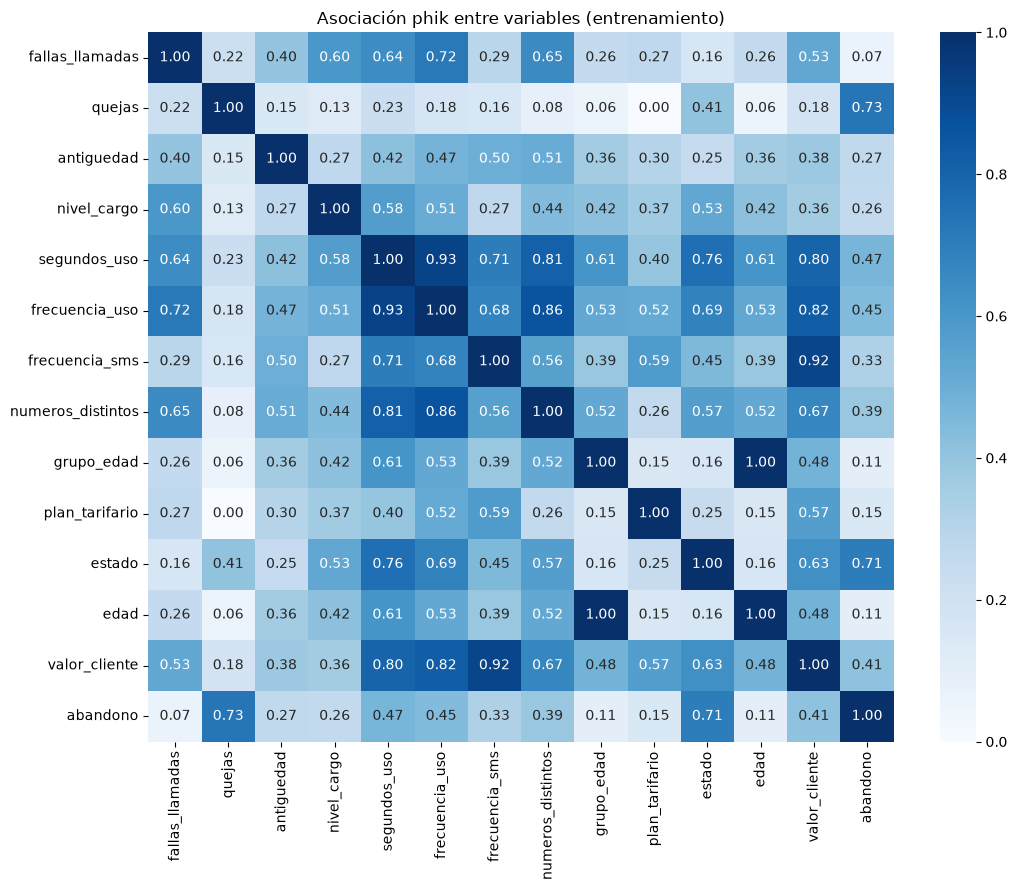

In [23]:
matriz_phik = train.phik_matrix(interval_cols=columnas_numericas, njobs=1)

plt.figure(figsize=(11, 9))
sns.heatmap(matriz_phik, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Asociación phik entre variables (entrenamiento)")
plt.tight_layout()
plt.show()


In [24]:
asociacion_abandono = matriz_phik["abandono"].drop("abandono").sort_values(ascending=False)

tabla_asociacion = asociacion_abandono.round(3).reset_index()
tabla_asociacion.columns = ["Variable", "phik con abandono"]
tabla_asociacion


,Variable,phik con abandono
0,quejas,0.734
1,estado,0.705
2,segundos_uso,0.469
3,frecuencia_uso,0.445
4,valor_cliente,0.413
5,numeros_distintos,0.389
6,frecuencia_sms,0.325
7,antiguedad,0.267
8,nivel_cargo,0.262
9,plan_tarifario,0.152


Encabezan quejas con 0,734 y estado con 0,705, seguidas por el bloque de uso: segundos_uso 0,469, frecuencia_uso 0,445, valor_cliente 0,413, numeros_distintos 0,389 y frecuencia_sms 0,325.

Al final quedan plan_tarifario 0,152, grupo_edad y edad 0,105, y fallas_llamadas 0,066.

### 6.7. Variables que repiten información

Buscamos parejas de entradas con phik de 0,60 o más: si dos variables dicen lo mismo, el modelo no gana nada con las dos.

In [25]:
entradas_phik = matriz_phik.drop(index="abandono", columns="abandono")

rows = []

for i in range(len(entradas_phik.columns)):
    for j in range(i + 1, len(entradas_phik.columns)):
        valor = entradas_phik.iloc[i, j]
        if valor >= 0.60:
            rows.append({
                "Variable A": entradas_phik.columns[i],
                "Variable B": entradas_phik.columns[j],
                "phik": round(valor, 3)
            })

tabla_redundancia = pd.DataFrame(rows)

if len(tabla_redundancia) > 0:
    tabla_redundancia = tabla_redundancia.sort_values("phik", ascending=False)

tabla_redundancia


,Variable A,Variable B,phik
17,grupo_edad,edad,1.000
4,segundos_uso,frecuencia_uso,0.928
15,frecuencia_sms,valor_cliente,0.918
12,frecuencia_uso,numeros_distintos,0.865
14,frecuencia_uso,valor_cliente,0.821
6,segundos_uso,numeros_distintos,0.812
10,segundos_uso,valor_cliente,0.798
8,segundos_uso,estado,0.755
2,fallas_llamadas,frecuencia_uso,0.720
5,segundos_uso,frecuencia_sms,0.706


Revisamos aparte la relación entre edad y grupo_edad.

In [26]:
relacion_edades = train[["edad", "grupo_edad"]].drop_duplicates().sort_values("edad")

print("Grupos distintos por edad:", train.groupby("edad")["grupo_edad"].nunique().max())
print("Edades distintas por grupo:", train.groupby("grupo_edad")["edad"].nunique().max())

relacion_edades


Grupos distintos por edad: 1
Edades distintas por grupo: 1


,edad,grupo_edad
1,15,1
3,25,2
0,30,3
2,45,4
18,55,5


Hay 19 parejas con phik de 0,60 o más. El caso extremo es edad y grupo_edad, con phik de 1,000: cada edad pertenece a un solo grupo y cada grupo tiene una sola edad (15 a 1, 25 a 2, 30 a 3, 45 a 4 y 55 a 5), así que son la misma variable escrita de dos maneras.

Las variables de uso también se solapan: segundos_uso con frecuencia_uso 0,928, frecuencia_sms con valor_cliente 0,918 y frecuencia_uso con numeros_distintos 0,865. Cada una mide algo distinto, así que se quedan.

### 6.8. Quitamos edad

Conservar las dos no aporta nada y sí estorba: en los modelos de distancia la edad contaría doble, en los árboles su importancia se repartiría entre las dos copias y en la selección ocuparían dos puestos para decir lo mismo.

Quitamos edad y conservamos grupo_edad, que es la forma documentada por UCI. No se pierde información, porque cada grupo corresponde a una sola edad.

In [27]:
train = train.drop(columns="edad")
test = test.drop(columns="edad")

X_train = train.drop(columns="abandono")
y_train = train["abandono"]
X_test = test.drop(columns="abandono")
y_test = test["abandono"]

columnas_numericas.remove("edad")

print("Variables de entrada:", X_train.shape[1])
print("Entrenamiento:", train.shape, "| Prueba:", test.shape)

list(X_train.columns)


Variables de entrada: 12
Entrenamiento: (2520, 13) | Prueba: (630, 13)


['fallas_llamadas',
 'quejas',
 'antiguedad',
 'nivel_cargo',
 'segundos_uso',
 'frecuencia_uso',
 'frecuencia_sms',
 'numeros_distintos',
 'grupo_edad',
 'plan_tarifario',
 'estado',
 'valor_cliente']

### 6.9. Estado y valor del cliente

Estas dos entradas merecen una revisión aparte. De estado no sabemos qué cuenta como activo, y de valor_cliente no conocemos la fórmula, así que conviene comprobar que aportan algo y que ese algo no viene de otra variable.

De estado queremos saber si dice algo por su cuenta o si solo repite lo que ya dicen las quejas, que son la señal más fuerte. Lo miramos entre los clientes que no pusieron ninguna queja.

In [28]:
sin_quejas = train[train["quejas"] == 0]

rows = []

for valor in [1, 2]:
    grupo = sin_quejas[sin_quejas["estado"] == valor]
    rows.append({
        "estado": valor,
        "Clientes": len(grupo),
        "Abandonos": int(grupo["abandono"].sum()),
        "% Abandono": round(grupo["abandono"].mean() * 100, 2)
    })

tabla_estado = pd.DataFrame(rows)
tabla_estado


,estado,Clientes,Abandonos,% Abandono
0,1,1824,50,2.74
1,2,494,183,37.04


Entre los 2.318 clientes que no pusieron ninguna queja abandona el 37,04 % de los 494 no activos y el 2,74 % de los 1.824 activos: trece veces más. Estado separa por su cuenta, sin apoyarse en las quejas, y concentra 183 de los 233 abandonos de ese grupo en uno de cada cinco clientes.

De valor_cliente queremos saber si trae información nueva. Si las demás entradas lo reconstruyen, es una combinación de ellas y no una medición aparte. Lo medimos con una regresión que intenta reproducirlo a partir de las otras once.

In [29]:
from sklearn.linear_model import LinearRegression

entradas_sin_valor = []

for columna in X_train.columns:
    if columna != "valor_cliente":
        entradas_sin_valor.append(columna)

reconstruccion = LinearRegression()
reconstruccion.fit(train[entradas_sin_valor], train["valor_cliente"])

print("R2 de valor_cliente a partir de las demás entradas:",
      round(reconstruccion.score(train[entradas_sin_valor], train["valor_cliente"]), 4))


R2 de valor_cliente a partir de las demás entradas: 0.9807


Las demás entradas explican el 98 % de la variación de valor_cliente, así que es una combinación de ellas.

Las dos se conservan.

Quedan 12 entradas más abandono. Quitamos la columna también de test para que los dos conjuntos tengan las mismas variables. Es la única variable que eliminamos.

Las señales más fuertes son las quejas y el estado del cliente, seguidas por el uso: quien abandona consume cerca de un tercio. Las distribuciones están sesgadas a la derecha y en escalas muy distintas, que es lo que atiende la preparación de la sección siguiente.

[Volver al índice](#indice)

<a id="seccion-7"></a>
## 7. Preparación de los datos

La preparación es lo que ocurre entre los datos y el modelo: escalar las variables y decidir si conviene reducirlas o seleccionar unas pocas. Aquí decidimos qué hacer; lo aplicamos en la sección siguiente.

Nada se aplica sobre la tabla completa. Cada paso se ajusta con la parte de entrenamiento de cada partición y después se aplica a la parte que se evalúa, como en el cuaderno de normalización de clase.

### 7.1. Escalado

Las variables están en escalas muy distintas, desde antiguedad entre 3 y 47 hasta segundos_uso que llega a 16.980, y sus distribuciones están sesgadas.

Los modelos que miden distancias, como KNN o SVM, comparan las variables entre sí, así que sin escalar quedarían dominados por segundos_uso y valor_cliente. A los árboles no les afecta, porque cortan cada variable por separado.

Usamos MinMaxScaler, que lleva cada variable al rango de 0 a 1. Conserva la forma de la distribución y deja los ceros en cero, que aquí significan algo: un cliente sin uso. StandardScaler centra en la media y divide por la desviación, lo que encaja mejor con distribuciones simétricas; con colas tan largas como estas, la media queda lejos de donde está la mayoría de los clientes.

El escalador se ajusta con el entrenamiento y se aplica a los dos conjuntos, nunca al revés. En la comparación de modelos eso se repite dentro de cada partición.

### 7.2. Selección de variables

Con doce entradas no tenemos un problema de tamaño, pero sí vimos variables que casi no se mueven con el abandono y otras que se repiten entre sí. Miramos las dos herramientas habituales antes de decidir.

ANOVA puntúa cada variable por separado según cuánto separa a los dos grupos. PCA no mira el abandono: resume las variables en componentes nuevas que concentran la variación de los datos.

Empezamos por ANOVA. La prueba compara, para cada variable, el promedio de quienes abandonan con el de quienes permanecen. Un valor de F alto significa que los dos grupos están lejos, y un p pequeño que esa distancia difícilmente se explica por azar.

In [30]:
from sklearn.feature_selection import f_classif

valores_f, valores_p = f_classif(X_train, y_train)

tabla_anova = pd.DataFrame({
    "Variable": X_train.columns,
    "F": valores_f.round(2),
    "p": valores_p.round(4)
})

tabla_anova = tabla_anova.sort_values("F", ascending=False)
tabla_anova


,Variable,F,p
1,quejas,968.57,0.0000
10,estado,839.51,0.0000
5,frecuencia_uso,259.48,0.0000
4,segundos_uso,252.24,0.0000
11,valor_cliente,229.31,0.0000
7,numeros_distintos,212.87,0.0000
6,frecuencia_sms,128.76,0.0000
3,nivel_cargo,108.20,0.0000
9,plan_tarifario,26.14,0.0000
2,antiguedad,4.49,0.0343


El orden coincide con el que dio phik: quejas con F de 968,57 y estado con 839,51 muy por delante, después el bloque de uso entre 259 y 128, y nivel_cargo con 108,20.

Al final quedan plan_tarifario con 26,14, antiguedad con 4,49 y p de 0,0343, y dos variables sin relación aparente: fallas_llamadas con F de 0,68 y p de 0,41, y grupo_edad con 0,11 y p de 0,74. Con esos p no podemos afirmar que sus promedios cambien entre quienes abandonan y quienes permanecen.

Conviene leerlo con cuidado. ANOVA mira cada variable sola y compara promedios, así que una F baja no quiere decir que la variable sea inútil: puede aportar combinada con otras, o separar los grupos de una forma que esta prueba no capta.

Seguimos con PCA. Lo aplicamos sobre los datos escalados, porque las componentes se construyen buscando la mayor variación y sin escalar se las llevarían las variables de números grandes. Ajustamos el escalador con el entrenamiento, como quedó dicho en 7.1, y miramos cuánta variación conserva cada cantidad de componentes.

In [31]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA

norm = MinMaxScaler().fit(X_train)
X_train_norm = norm.transform(X_train)

componentes = PCA()
componentes.fit(X_train_norm)

varianza_acumulada = componentes.explained_variance_ratio_.cumsum()

rows = []

for i in range(len(varianza_acumulada)):
    rows.append({
        "Componentes": i + 1,
        "% de varianza acumulada": round(varianza_acumulada[i] * 100, 2)
    })

tabla_pca = pd.DataFrame(rows)
tabla_pca


,Componentes,% de varianza acumulada
0,1,38.11
1,2,52.74
2,3,64.89
3,4,74.43
4,5,82.63
5,6,89.37
6,7,93.68
7,8,96.70
8,9,98.52
9,10,99.71


La compresión es escasa. Hacen falta siete componentes para conservar el 90 % de la variación y ocho para el 95 %, partiendo de doce variables. Las dos primeras juntas apenas reúnen el 52,74 %.

Es coherente con lo que vimos en 6.7: las variables de uso se solapan entre sí, pero las categóricas aportan variación propia que no se deja resumir.

### 7.3. Decisión

Descartamos PCA. Pasar de doce variables a siete componentes no compensa lo que cuesta: cada componente es una mezcla de todas las variables, y perderíamos poder explicar por qué un cliente está en riesgo, que es justo lo que el equipo de retención necesita para la llamada. Tampoco resuelve ningún problema de tamaño, porque no lo tenemos.

No quitamos variables todavía. Las dos que ANOVA deja al final podrían aportar combinadas con otras, y los modelos de árbol las ignoran solos si no sirven. En vez de decidirlo con una prueba que mira cada variable por separado, comparamos en la sección siguiente los modelos con todas las variables y con la selección ANOVA, que es donde se puede medir si quitar variables ayuda o estorba.

La preparación queda entonces en escalado con MinMaxScaler, con la selección ANOVA como alternativa a medir.

[Volver al índice](#indice)

<a id="seccion-8"></a>
## 8. Modelado

Comparamos doce clasificadores y, para cada uno, varias formas de tratar el desbalance. Todo se mide con validación cruzada sobre entrenamiento; la prueba sigue reservada.

El objetivo de esta sección no es afinar ningún modelo, sino ver cuáles prometen. Los tres mejores pasan a la sección 9, donde se ajustan sus hiperparámetros.

### 8.1. Los doce modelos

Van desde los más simples, como Naive Bayes o un árbol, hasta conjuntos de modelos como Random Forest, Gradient Boosting o Stacking, que combina tres modelos distintos y usa una regresión logística para decidir entre ellos. Todos se crean con random_state=42 donde aplica.

In [32]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import StackingClassifier

modelos = [
    ("KNN", KNeighborsClassifier(n_neighbors=5)),
    ("Naive Bayes", GaussianNB()),
    ("Árbol de decisión", DecisionTreeClassifier(random_state=42)),
    ("Regresión logística", LogisticRegression(max_iter=2000, random_state=42)),
    ("SVM", SVC(random_state=42)),
    ("SVM lineal", LinearSVC(max_iter=10000, random_state=42)),
    ("Red neuronal", MLPClassifier(max_iter=1000, random_state=42)),
    ("Random Forest", RandomForestClassifier(n_estimators=200, random_state=42)),
    ("Bagging", BaggingClassifier(random_state=42)),
    ("AdaBoost", AdaBoostClassifier(random_state=42)),
    ("Gradient Boosting", GradientBoostingClassifier(random_state=42)),
    ("Stacking", StackingClassifier(
        estimators=[
            ("rf", RandomForestClassifier(n_estimators=200, random_state=42)),
            ("svm", SVC(random_state=42)),
            ("knn", KNeighborsClassifier(n_neighbors=5))
        ],
        final_estimator=LogisticRegression(max_iter=2000),
        cv=5
    ))
]

print("Modelos a comparar:", len(modelos))


Modelos a comparar: 12


### 8.2. Estrategias para el desbalance

Solo el 15,7 % de los clientes abandona, así que un modelo puede acertar mucho ignorando por completo a la minoría. Probamos cuatro formas de tratarlo:

Sin balanceo deja los datos como están y sirve de punto de comparación. Peso por clase le dice al modelo que equivoque menos a la minoría, y solo lo admiten algunos. SMOTENC crea clientes sintéticos de la clase minoritaria combinando los que ya existen, respetando que quejas, plan_tarifario y estado son categorías y no admiten promedios. Submuestreo descarta clientes de la mayoría hasta igualar los dos grupos.

Con los doce modelos salen 41 combinaciones: treinta y seis de los modelos por las tres estrategias que todos admiten, más cinco de peso por clase.

In [33]:
from imblearn.over_sampling import SMOTENC
from imblearn.under_sampling import RandomUnderSampler

modelos_con_peso = [
    ("Árbol de decisión", DecisionTreeClassifier(class_weight="balanced", random_state=42)),
    ("Regresión logística", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42)),
    ("SVM", SVC(class_weight="balanced", random_state=42)),
    ("SVM lineal", LinearSVC(class_weight="balanced", max_iter=10000, random_state=42)),
    ("Random Forest", RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42))
]

combinaciones = []

for nombre_modelo, modelo in modelos:
    for estrategia in ["Sin balanceo", "SMOTENC", "Submuestreo"]:
        combinaciones.append((nombre_modelo, modelo, estrategia))

for nombre_modelo, modelo in modelos_con_peso:
    combinaciones.append((nombre_modelo, modelo, "Peso por clase"))

columnas_smotenc = []

for columna in X_train.columns:
    if columna in ["quejas", "plan_tarifario", "estado"]:
        columnas_smotenc.append(X_train.columns.get_loc(columna))

print("Combinaciones a evaluar:", len(combinaciones))
print("Columnas categóricas para SMOTENC:", columnas_smotenc)


Combinaciones a evaluar: 41
Columnas categóricas para SMOTENC: [1, 9, 10]


### 8.3. La comparación

Recorremos las diez particiones a mano. En cada vuelta separamos la parte de entrenamiento de la que se evalúa, ajustamos el escalador solo con la primera y se lo aplicamos a las dos, y después aplicamos el balanceo únicamente a la parte de entrenamiento. Así el modelo nunca ve nada de la parte con la que se lo mide, ni siquiera a través del escalado o de los clientes sintéticos.

Usamos clone para que cada combinación empiece con un modelo nuevo y sin entrenar.

Esta celda es la más pesada del cuaderno: son 41 combinaciones por diez particiones, y Stacking, SVM y la red neuronal son lentos. Imprime una línea por combinación para poder seguir el avance.

In [34]:
import time
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score

particiones = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

rows = []

for nombre_modelo, modelo, estrategia in combinaciones:
    inicio = time.time()
    f1_particiones = []
    precision_particiones = []
    recall_particiones = []

    for indices_entrenamiento, indices_evaluacion in particiones.split(X_train, y_train):
        X_train_cv = X_train.iloc[indices_entrenamiento]
        X_test_cv = X_train.iloc[indices_evaluacion]
        y_train_cv = y_train.iloc[indices_entrenamiento]
        y_test_cv = y_train.iloc[indices_evaluacion]

        norm = MinMaxScaler().fit(X_train_cv)
        X_train_cv = norm.transform(X_train_cv)
        X_test_cv = norm.transform(X_test_cv)

        if estrategia == "SMOTENC":
            muestreador = SMOTENC(categorical_features=columnas_smotenc, random_state=42)
            X_train_cv, y_train_cv = muestreador.fit_resample(X_train_cv, y_train_cv)
        elif estrategia == "Submuestreo":
            muestreador = RandomUnderSampler(random_state=42)
            X_train_cv, y_train_cv = muestreador.fit_resample(X_train_cv, y_train_cv)

        clasificador = clone(modelo)
        clasificador.fit(X_train_cv, y_train_cv)
        predicciones = clasificador.predict(X_test_cv)

        f1_particiones.append(f1_score(y_test_cv, predicciones, zero_division=0))
        precision_particiones.append(precision_score(y_test_cv, predicciones, zero_division=0))
        recall_particiones.append(recall_score(y_test_cv, predicciones, zero_division=0))

    duracion = time.time() - inicio
    f1_medio = sum(f1_particiones) / len(f1_particiones)

    rows.append({
        "Modelo": nombre_modelo,
        "Estrategia": estrategia,
        "F1": round(f1_medio, 4),
        "Desviación F1": round(pd.Series(f1_particiones).std(), 4),
        "Precisión": round(sum(precision_particiones) / len(precision_particiones), 4),
        "Recall": round(sum(recall_particiones) / len(recall_particiones), 4),
        "Segundos": round(duracion, 1)
    })

    print(nombre_modelo, "+", estrategia, "-> F1", round(f1_medio, 4),
          "(" + str(round(duracion, 1)) + " s)")

comparacion = pd.DataFrame(rows)
print("\nCombinaciones evaluadas:", len(comparacion))


KNN + Sin balanceo -> F1 0.8242 (0.1 s)


KNN + SMOTENC -> F1 0.8056 (0.3 s)
KNN + Submuestreo -> F1 0.7353 (0.0 s)
Naive Bayes + Sin balanceo -> F1 0.5323 (0.0 s)


Naive Bayes + SMOTENC -> F1 0.4937 (0.3 s)
Naive Bayes + Submuestreo -> F1 0.4973 (0.0 s)
Árbol de decisión + Sin balanceo -> F1 0.8056 (0.1 s)


Árbol de decisión + SMOTENC -> F1 0.8017 (0.3 s)
Árbol de decisión + Submuestreo -> F1 0.7497 (0.0 s)
Regresión logística + Sin balanceo -> F1 0.5395 (0.0 s)


Regresión logística + SMOTENC -> F1 0.6556 (0.3 s)
Regresión logística + Submuestreo -> F1 0.6582 (0.0 s)


SVM + Sin balanceo -> F1 0.5621 (0.2 s)


SVM + SMOTENC -> F1 0.6691 (0.7 s)
SVM + Submuestreo -> F1 0.6633 (0.1 s)
SVM lineal + Sin balanceo -> F1 0.5515 (0.0 s)


SVM lineal + SMOTENC -> F1 0.6539 (0.3 s)
SVM lineal + Submuestreo -> F1 0.6523 (0.0 s)


Red neuronal + Sin balanceo -> F1 0.8498 (12.5 s)


Red neuronal + SMOTENC -> F1 0.8432 (17.9 s)


/Users/martinrestrepocoral/Desktop/IA/prediccion-sismica-minas/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


/Users/martinrestrepocoral/Desktop/IA/prediccion-sismica-minas/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


/Users/martinrestrepocoral/Desktop/IA/prediccion-sismica-minas/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


/Users/martinrestrepocoral/Desktop/IA/prediccion-sismica-minas/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


/Users/martinrestrepocoral/Desktop/IA/prediccion-sismica-minas/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


/Users/martinrestrepocoral/Desktop/IA/prediccion-sismica-minas/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


/Users/martinrestrepocoral/Desktop/IA/prediccion-sismica-minas/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


/Users/martinrestrepocoral/Desktop/IA/prediccion-sismica-minas/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


/Users/martinrestrepocoral/Desktop/IA/prediccion-sismica-minas/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


/Users/martinrestrepocoral/Desktop/IA/prediccion-sismica-minas/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


Red neuronal + Submuestreo -> F1 0.7352 (5.4 s)


Random Forest + Sin balanceo -> F1 0.8338 (1.9 s)


Random Forest + SMOTENC -> F1 0.8665 (3.3 s)


Random Forest + Submuestreo -> F1 0.7676 (1.0 s)


Bagging + Sin balanceo -> F1 0.8335 (0.3 s)


Bagging + SMOTENC -> F1 0.8329 (0.7 s)
Bagging + Submuestreo -> F1 0.7634 (0.1 s)


AdaBoost + Sin balanceo -> F1 0.6624 (0.5 s)


AdaBoost + SMOTENC -> F1 0.6823 (1.0 s)


AdaBoost + Submuestreo -> F1 0.6769 (0.3 s)


Gradient Boosting + Sin balanceo -> F1 0.8073 (1.7 s)


Gradient Boosting + SMOTENC -> F1 0.7804 (3.3 s)


Gradient Boosting + Submuestreo -> F1 0.7419 (0.6 s)


Stacking + Sin balanceo -> F1 0.858 (10.5 s)


Stacking + SMOTENC -> F1 0.8702 (18.4 s)


Stacking + Submuestreo -> F1 0.7772 (5.6 s)
Árbol de decisión + Peso por clase -> F1 0.8064 (0.1 s)
Regresión logística + Peso por clase -> F1 0.6565 (0.1 s)


SVM + Peso por clase -> F1 0.6674 (0.2 s)
SVM lineal + Peso por clase -> F1 0.6531 (0.0 s)


Random Forest + Peso por clase -> F1 0.8717 (1.9 s)

Combinaciones evaluadas: 41


### 8.4. Resultados

Ordenamos las 41 combinaciones por F1 del abandono.

In [35]:
comparacion_ordenada = comparacion.sort_values("F1", ascending=False).reset_index(drop=True)
comparacion_ordenada


,Modelo,Estrategia,F1,Desviación F1,Precisión,Recall,Segundos
0,Random Forest,Peso por clase,0.8717,0.0399,0.8514,0.8940,1.9
1,Stacking,SMOTENC,0.8702,0.0346,0.8578,0.8841,18.4
2,Random Forest,SMOTENC,0.8665,0.0368,0.8563,0.8789,3.3
3,Stacking,Sin balanceo,0.8580,0.0265,0.8878,0.8309,10.5
4,Red neuronal,Sin balanceo,0.8498,0.0318,0.8756,0.8285,12.5
5,Red neuronal,SMOTENC,0.8432,0.0324,0.7658,0.9394,17.9
6,Random Forest,Sin balanceo,0.8338,0.0341,0.8872,0.7881,1.9
7,Bagging,Sin balanceo,0.8335,0.0265,0.8769,0.7956,0.3
8,Bagging,SMOTENC,0.8329,0.0525,0.8294,0.8387,0.7
9,KNN,Sin balanceo,0.8242,0.0481,0.8445,0.8058,0.1


Encabezan Random Forest con peso por clase (0,8717), Stacking con SMOTENC (0,8702) y Random Forest con SMOTENC (0,8665). Entre los tres hay cinco milésimas de diferencia, bastante menos que la desviación entre particiones, que ronda 0,035, así que no hay un ganador claro.

La separación grande no está entre estrategias sino entre familias de modelos. Los árboles y sus conjuntos, junto con la red neuronal y KNN, pasan de 0,80. La regresión logística, los dos SVM y Naive Bayes se quedan por debajo de 0,70. Con doce variables y relaciones que no son líneas rectas, los modelos que parten el espacio en regiones aprovechan mejor los datos.

Llama la atención la esquina de arriba a la derecha: sin balanceo, la regresión logística y los SVM tienen precisión alta, entre 0,80 y 0,90, pero F1 de 0,54 a 0,56. Avisan poco y casi siempre aciertan cuando avisan, que es justo lo contrario de lo que necesita el equipo de retención.

Una advertencia de la salida: la red neuronal llegó al máximo de mil iteraciones sin converger en varias particiones. Sus resultados hay que leerlos con esa reserva.

Para ver si el balanceo importa más que el modelo, miramos el F1 promedio de cada estrategia y el mejor resultado que alcanza cada una.

In [36]:
rows = []

for estrategia in ["Sin balanceo", "Peso por clase", "SMOTENC", "Submuestreo"]:
    grupo = comparacion[comparacion["Estrategia"] == estrategia]
    rows.append({
        "Estrategia": estrategia,
        "Combinaciones": len(grupo),
        "F1 promedio": round(grupo["F1"].mean(), 4),
        "Mejor F1": round(grupo["F1"].max(), 4),
        "Recall promedio": round(grupo["Recall"].mean(), 4)
    })

resumen_estrategias = pd.DataFrame(rows)
resumen_estrategias


,Estrategia,Combinaciones,F1 promedio,Mejor F1,Recall promedio
0,Sin balanceo,12,0.7217,0.8580,0.6947
1,Peso por clase,5,0.7310,0.8717,0.8889
2,SMOTENC,12,0.7463,0.8702,0.8906
3,Submuestreo,12,0.7015,0.7772,0.9240


SMOTENC es la estrategia con mejor promedio (0,7463), seguida del peso por clase (0,7310), que solo aplica a cinco combinaciones, y de no balancear (0,7217). El submuestreo queda último con 0,7015.

El submuestreo tiene el mejor recall promedio, 0,9240, y aun así el peor F1: detecta casi todos los abandonos a costa de muchas falsas alarmas. Es esperable, porque para igualar los dos grupos hay que descartar más del 80 % de los clientes que permanecen y el modelo se queda con muy pocos datos.

El balanceo pesa más en unos modelos que en otros. La regresión logística pasa de 0,5395 sin balanceo a 0,6582 con submuestreo, mientras que Random Forest solo sube de 0,8338 a 0,8717 con peso por clase. Los modelos de árbol ya manejaban el desbalance razonablemente bien.

### 8.5. Los tres candidatos

Nos quedamos con las tres mejores combinaciones por F1, sin repetir modelo, para que los candidatos sean de familias distintas y no tres versiones del mismo.

In [37]:
candidatos = []
modelos_elegidos = []

for i in range(len(comparacion_ordenada)):
    fila = comparacion_ordenada.iloc[i]
    if fila["Modelo"] not in modelos_elegidos and len(candidatos) < 3:
        candidatos.append({
            "Modelo": fila["Modelo"],
            "Estrategia": fila["Estrategia"],
            "F1": fila["F1"],
            "Desviación F1": fila["Desviación F1"],
            "Recall": fila["Recall"]
        })
        modelos_elegidos.append(fila["Modelo"])

tabla_candidatos = pd.DataFrame(candidatos)
tabla_candidatos


,Modelo,Estrategia,F1,Desviación F1,Recall
0,Random Forest,Peso por clase,0.8717,0.0399,0.8940
1,Stacking,SMOTENC,0.8702,0.0346,0.8841
2,Red neuronal,Sin balanceo,0.8498,0.0318,0.8285


Los tres candidatos son Random Forest con peso por clase (F1 0,8717), Stacking con SMOTENC (0,8702) y la red neuronal sin balanceo (0,8498).

Los tres caben dentro de una desviación, así que el orden puede cambiar cuando ajustemos sus hiperparámetros en la sección 9. También conviene anotar la diferencia de costo: Random Forest tarda unos dos segundos en las diez particiones, mientras Stacking y la red neuronal pasan de diez, y eso cuenta si el modelo hay que reentrenarlo seguido.

### 8.6. ¿Conviene quitar variables?

En la sección 7 dejamos pendiente medir la selección ANOVA en lugar de decidirla por nuestra cuenta. La probamos ahora solo con los tres candidatos, comparando las doce variables con quedarse con las diez o las ocho mejores.

La selección va dentro del mismo ciclo, después del escalado y del balanceo, de modo que cada partición elige sus variables con sus propios datos.

In [38]:
from sklearn.feature_selection import SelectKBest

combinaciones_candidatas = []

for i in range(len(tabla_candidatos)):
    fila = tabla_candidatos.iloc[i]
    for nombre_modelo, modelo, estrategia in combinaciones:
        if nombre_modelo == fila["Modelo"] and estrategia == fila["Estrategia"]:
            combinaciones_candidatas.append((nombre_modelo, modelo, estrategia))

rows = []

for nombre_modelo, modelo, estrategia in combinaciones_candidatas:
    for k in [8, 10, 12]:
        f1_particiones = []

        for indices_entrenamiento, indices_evaluacion in particiones.split(X_train, y_train):
            X_train_cv = X_train.iloc[indices_entrenamiento]
            X_test_cv = X_train.iloc[indices_evaluacion]
            y_train_cv = y_train.iloc[indices_entrenamiento]
            y_test_cv = y_train.iloc[indices_evaluacion]

            norm = MinMaxScaler().fit(X_train_cv)
            X_train_cv = norm.transform(X_train_cv)
            X_test_cv = norm.transform(X_test_cv)

            if estrategia == "SMOTENC":
                muestreador = SMOTENC(categorical_features=columnas_smotenc, random_state=42)
                X_train_cv, y_train_cv = muestreador.fit_resample(X_train_cv, y_train_cv)
            elif estrategia == "Submuestreo":
                muestreador = RandomUnderSampler(random_state=42)
                X_train_cv, y_train_cv = muestreador.fit_resample(X_train_cv, y_train_cv)

            if k < X_train.shape[1]:
                selector = SelectKBest(f_classif, k=k).fit(X_train_cv, y_train_cv)
                X_train_cv = selector.transform(X_train_cv)
                X_test_cv = selector.transform(X_test_cv)

            clasificador = clone(modelo)
            clasificador.fit(X_train_cv, y_train_cv)
            predicciones = clasificador.predict(X_test_cv)

            f1_particiones.append(f1_score(y_test_cv, predicciones, zero_division=0))

        rows.append({
            "Modelo": nombre_modelo,
            "Estrategia": estrategia,
            "Variables": k,
            "F1": round(sum(f1_particiones) / len(f1_particiones), 4)
        })

comparacion_seleccion = pd.DataFrame(rows)
comparacion_seleccion


/Users/martinrestrepocoral/Desktop/IA/prediccion-sismica-minas/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


/Users/martinrestrepocoral/Desktop/IA/prediccion-sismica-minas/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


,Modelo,Estrategia,Variables,F1
0,Random Forest,Peso por clase,8,0.7823
1,Random Forest,Peso por clase,10,0.8172
2,Random Forest,Peso por clase,12,0.8717
3,Stacking,SMOTENC,8,0.7932
4,Stacking,SMOTENC,10,0.8294
5,Stacking,SMOTENC,12,0.8702
6,Red neuronal,Sin balanceo,8,0.6905
7,Red neuronal,Sin balanceo,10,0.7734
8,Red neuronal,Sin balanceo,12,0.8498


Quitar variables empeora a los tres candidatos, y no por poco. Random Forest baja de 0,8717 con las doce a 0,8172 con diez y a 0,7823 con ocho. Stacking cae de forma parecida, de 0,8702 a 0,8294 y 0,7932, y la red neuronal es la más sensible: de 0,8498 a 0,6905.

Es un buen recordatorio de lo que advertíamos en 7.2. Las dos variables que ANOVA dejaba al final, grupo_edad y fallas_llamadas, son las primeras que se descartan al bajar a diez, y perderlas cuesta más de cinco centésimas de F1. Por separado no distinguen a quienes abandonan, pero combinadas con las demás sí aportan, y esta prueba lo mide en vez de suponerlo.

Nos quedamos con las doce variables, sin selección.

### Cierre de la sección

De 41 combinaciones salen tres candidatos: Random Forest con peso por clase (F1 0,8717), Stacking con SMOTENC (0,8702) y la red neuronal sin balanceo (0,8498). Los modelos de árbol y sus conjuntos dominan con claridad sobre los lineales, el balanceo ayuda pero menos de lo que separa a las familias, y la preparación se queda en el escalado.

En la siguiente sección ajustamos los hiperparámetros de estos tres, siempre con entrenamiento.

[Volver al índice](#indice)

<a id="seccion-9"></a>
## 9. Ajuste de hiperparámetros

Hasta ahora los tres candidatos corrieron con sus valores por defecto. Aquí probamos algunas variantes de cada uno, siempre con las mismas diez particiones del entrenamiento.

Las grillas son pequeñas a propósito: cada configuración se evalúa diez veces y Stacking tarda unos segundos en cada una, así que una grilla grande costaría media hora sin cambiar el resultado.

### 9.1. Por qué el ajuste va con Pipeline

GridSearchCV llama directamente al fit del modelo con los datos que uno le pasa: entre partir los datos y entrenar no hay dónde meter el escalado ni el balanceo. Si los aplicáramos antes, sobre todo el entrenamiento, aprenderían también de las filas que después se usan para evaluar.

Con SMOTENC el problema es mayor. Crea clientes nuevos interpolando entre los que abandonaron, así que algunos sintéticos saldrían de clientes que luego se evalúan, y además las particiones de evaluación quedarían mitad y mitad, cuando la realidad es 15,7 % de abandono.

La solución es entregarle a GridSearchCV un solo objeto que lleve los pasos adentro: el Pipeline de imbalanced-learn. SMOTENC no transforma filas, las crea, y ese Pipeline sabe que eso solo debe pasar al entrenar. Cuando GridSearchCV entrena, el escalado y el balanceo trabajan únicamente con las nueve partes de esa vuelta; cuando evalúa, el escalador aplica lo que aprendió y el balanceo no hace nada. Los clientes sintéticos nunca se construyen con las filas que se van a evaluar.

Armamos un flujo por candidato. Random Forest y la red neuronal no llevan balanceo, porque sus mejores estrategias fueron el peso por clase y ninguna.

In [39]:
from sklearn.model_selection import GridSearchCV
from imblearn.pipeline import Pipeline

flujo_random_forest = Pipeline([
    ("escalador", MinMaxScaler()),
    ("modelo", RandomForestClassifier(class_weight="balanced", random_state=42))
])

flujo_stacking = Pipeline([
    ("escalador", MinMaxScaler()),
    ("balanceo", SMOTENC(categorical_features=columnas_smotenc, random_state=42)),
    ("modelo", StackingClassifier(
        estimators=[
            ("rf", RandomForestClassifier(n_estimators=200, random_state=42)),
            ("svm", SVC(random_state=42)),
            ("knn", KNeighborsClassifier(n_neighbors=5))
        ],
        final_estimator=LogisticRegression(max_iter=2000),
        cv=5
    ))
])

flujo_red_neuronal = Pipeline([
    ("escalador", MinMaxScaler()),
    ("modelo", MLPClassifier(max_iter=2000, random_state=42))
])

flujo_stacking


,steps,"[('escalador', ...), ('balanceo', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
,categorical_features,"[1, 9, ...]"
,random_state,42
,categorical_encoder,None
,sampling_strategy,'auto'


### 9.2. Random Forest

Variamos cuántos árboles tiene, hasta dónde pueden crecer y cuántos clientes exige una hoja. Mantiene el peso por clase, que fue su mejor estrategia, y por eso su flujo no lleva balanceo.

In [40]:
grilla_random_forest = {
    "modelo__n_estimators": [100, 200, 400],
    "modelo__max_depth": [None, 10],
    "modelo__min_samples_leaf": [1, 2]
}

inicio = time.time()
busqueda_random_forest = GridSearchCV(
    flujo_random_forest, grilla_random_forest, cv=particiones, scoring="f1", n_jobs=-1
)
busqueda_random_forest.fit(X_train, y_train)

print("Mejor F1:", round(busqueda_random_forest.best_score_, 4))
print("Mejores parámetros:", busqueda_random_forest.best_params_)
print("Segundos:", round(time.time() - inicio, 1))

resultados_random_forest = pd.concat([
    pd.DataFrame(busqueda_random_forest.cv_results_["params"]),
    pd.DataFrame(busqueda_random_forest.cv_results_["mean_test_score"], columns=["F1"])
], axis=1)

resultados_random_forest.sort_values("F1", ascending=False)


Mejor F1: 0.8722
Mejores parámetros: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 400}
Segundos: 4.0


,modelo__max_depth,modelo__min_samples_leaf,modelo__n_estimators,F1
2,NaN,1,400,0.872200
1,NaN,1,200,0.871658
0,NaN,1,100,0.868294
5,NaN,2,400,0.862226
3,NaN,2,100,0.857931
4,NaN,2,200,0.856331
8,10.0,1,400,0.829634
6,10.0,1,100,0.821091
7,10.0,1,200,0.820529
10,10.0,2,200,0.820181


### 9.3. Stacking

Variamos el tamaño del bosque que lleva dentro y los vecinos del KNN. Este es el flujo que sí necesita el Pipeline, porque entre el escalado y el modelo va SMOTENC.

In [41]:
grilla_stacking = {
    "modelo__rf__n_estimators": [100, 200],
    "modelo__knn__n_neighbors": [5, 9]
}

inicio = time.time()
busqueda_stacking = GridSearchCV(
    flujo_stacking, grilla_stacking, cv=particiones, scoring="f1", n_jobs=-1
)
busqueda_stacking.fit(X_train, y_train)

print("Mejor F1:", round(busqueda_stacking.best_score_, 4))
print("Mejores parámetros:", busqueda_stacking.best_params_)
print("Segundos:", round(time.time() - inicio, 1))

resultados_stacking = pd.concat([
    pd.DataFrame(busqueda_stacking.cv_results_["params"]),
    pd.DataFrame(busqueda_stacking.cv_results_["mean_test_score"], columns=["F1"])
], axis=1)

resultados_stacking.sort_values("F1", ascending=False)


Mejor F1: 0.8734
Mejores parámetros: {'modelo__knn__n_neighbors': 9, 'modelo__rf__n_estimators': 100}
Segundos: 7.4


,modelo__knn__n_neighbors,modelo__rf__n_estimators,F1
2,9,100,0.873362
3,9,200,0.870521
1,5,200,0.870201
0,5,100,0.869211


### 9.4. Red neuronal

Variamos la forma de las capas ocultas y alpha, la penalización que evita que se ajuste demasiado. Le subimos el máximo de iteraciones a 2.000 porque en la sección 8 varias particiones llegaron al tope de 1.000 sin converger.

In [42]:
grilla_red_neuronal = {
    "modelo__hidden_layer_sizes": [(100,), (50,), (100, 50)],
    "modelo__alpha": [0.0001, 0.001]
}

inicio = time.time()
busqueda_red_neuronal = GridSearchCV(
    flujo_red_neuronal, grilla_red_neuronal, cv=particiones, scoring="f1", n_jobs=-1
)
busqueda_red_neuronal.fit(X_train, y_train)

print("Mejor F1:", round(busqueda_red_neuronal.best_score_, 4))
print("Mejores parámetros:", busqueda_red_neuronal.best_params_)
print("Segundos:", round(time.time() - inicio, 1))

resultados_red_neuronal = pd.concat([
    pd.DataFrame(busqueda_red_neuronal.cv_results_["params"]),
    pd.DataFrame(busqueda_red_neuronal.cv_results_["mean_test_score"], columns=["F1"])
], axis=1)

resultados_red_neuronal.sort_values("F1", ascending=False)


Mejor F1: 0.8721
Mejores parámetros: {'modelo__alpha': 0.0001, 'modelo__hidden_layer_sizes': (100, 50)}
Segundos: 6.7


,modelo__alpha,modelo__hidden_layer_sizes,F1
2,0.0001,"(100, 50)",0.872119
5,0.0010,"(100, 50)",0.867509
0,0.0001,"(100,)",0.849796
1,0.0001,"(50,)",0.841471
3,0.0010,"(100,)",0.841240
4,0.0010,"(50,)",0.837688


### 9.5. Comparación y modelo elegido

Reunimos el mejor resultado de cada búsqueda y lo comparamos con lo que daba el modelo por defecto en la sección 8.

In [43]:
busquedas = [
    ("Random Forest", busqueda_random_forest),
    ("Stacking", busqueda_stacking),
    ("Red neuronal", busqueda_red_neuronal)
]

rows = []

for nombre_modelo, busqueda in busquedas:
    for i in range(len(tabla_candidatos)):
        fila = tabla_candidatos.iloc[i]
        if fila["Modelo"] == nombre_modelo:
            rows.append({
                "Modelo": nombre_modelo,
                "F1 por defecto": fila["F1"],
                "F1 ajustado": round(busqueda.best_score_, 4),
                "Diferencia": round(busqueda.best_score_ - fila["F1"], 4),
                "Mejores parámetros": str(busqueda.best_params_)
            })

comparacion_ajuste = pd.DataFrame(rows)
comparacion_ajuste


,Modelo,F1 por defecto,F1 ajustado,Diferencia,Mejores parámetros
0,Random Forest,0.8717,0.8722,0.0005,"{'modelo__max_depth': None, 'modelo__min_sampl..."
1,Stacking,0.8702,0.8734,0.0032,"{'modelo__knn__n_neighbors': 9, 'modelo__rf__n..."
2,Red neuronal,0.8498,0.8721,0.0223,"{'modelo__alpha': 0.0001, 'modelo__hidden_laye..."


### 9.6. El modelo elegido

Los tres candidatos quedaron a milésimas, así que elegir el F1 más alto sería elegir por azar: la desviación entre particiones es de unas cuatro centésimas, treinta veces el margen que los separa. Con otra semilla de particiones el orden cambiaría.

Aplicamos entonces una regla conocida en vez de escoger a dedo: entre las configuraciones que estén dentro de un error estándar de la mejor, nos quedamos con la más rápida de entrenar. El error estándar es la desviación dividida por la raíz del número de particiones, y mide cuánto puede moverse el promedio por puro azar.

In [44]:
rows = []

for nombre_modelo, busqueda in busquedas:
    indice = busqueda.best_index_
    desviacion = busqueda.cv_results_["std_test_score"][indice]
    rows.append({
        "Modelo": nombre_modelo,
        "F1": round(busqueda.best_score_, 4),
        "Desviación": round(desviacion, 4),
        "Error estándar": round(desviacion / (10 ** 0.5), 4),
        "Segundos por ajuste": round(busqueda.cv_results_["mean_fit_time"][indice], 2)
    })

resumen_candidatos = pd.DataFrame(rows)
resumen_candidatos


,Modelo,F1,Desviación,Error estándar,Segundos por ajuste
0,Random Forest,0.8722,0.0326,0.0103,0.47
1,Stacking,0.8734,0.0418,0.0132,1.41
2,Red neuronal,0.8721,0.0348,0.0110,1.07


In [45]:
mejor_f1 = resumen_candidatos["F1"].max()
fila_mejor = resumen_candidatos["F1"].idxmax()
margen = resumen_candidatos.loc[fila_mejor, "Error estándar"]

empatados = resumen_candidatos[resumen_candidatos["F1"] >= mejor_f1 - margen]
elegido = empatados.sort_values("Segundos por ajuste").iloc[0]

print("Mejor F1:", mejor_f1, "| margen de un error estándar:", round(mejor_f1 - margen, 4))
print("Candidatos dentro del margen:", len(empatados))
print("Elegido por ser el más rápido:", elegido["Modelo"])


Mejor F1: 0.8734 | margen de un error estándar: 0.8602
Candidatos dentro del margen: 3
Elegido por ser el más rápido: Random Forest


In [46]:
for nombre_modelo, busqueda in busquedas:
    if nombre_modelo == elegido["Modelo"]:
        modelo_elegido = busqueda.best_estimator_
        nombre_elegido = nombre_modelo
        parametros_elegidos = busqueda.best_params_

print("Modelo final:", nombre_elegido)
print("Parámetros:", parametros_elegidos)
print("F1 de validación:", round(elegido["F1"], 4))

modelo_elegido


Modelo final: Random Forest
Parámetros: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 400}
F1 de validación: 0.8722


,steps,"[('escalador', ...), ('modelo', ...)]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](12,)","['fallas_llamadas','quejas','antiguedad',...,'plan_tarifario','estado', 'valor_cliente']"
n_features_in_,int,12
,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False


**Elegimos Random Forest con cuatrocientos árboles, sin límite de profundidad y peso por clase.**

Las razones por las que preferimos el modelo simple cuando el resultado empata:

- La diferencia con Stacking es de 0,0012 frente a una desviación de 0,04, así que no es reproducible; con otra semilla de particiones el orden se invertiría.

- Random Forest es un solo modelo, mientras Stacking entrena tres clasificadores más una regresión logística que decide entre ellos, cada uno con su propia validación interna.

- Random Forest permite saber qué variables pesaron en cada predicción, que es lo que el equipo de retención necesita para preparar la llamada. Es el mismo argumento con el que descartamos PCA en la sección 7.

- Con peso por clase no hay remuestreo, así que no hay clientes sintéticos que explicar ni decisiones sobre qué variables son categóricas para SMOTENC. Una pieza menos en el flujo final.



[Volver al índice](#indice)

<a id="seccion-10"></a>
## 10. Calibración y umbral

El modelo no solo dice sí o no: entrega una probabilidad de abandono para cada cliente. De esa probabilidad dependen dos cosas distintas.

La primera es el orden de la lista que recibe el equipo de retención, y para eso la probabilidad debe querer decir lo que dice: si el modelo asigna 0,30 a un grupo de clientes, deberían abandonar cerca del 30 % de ellos. Eso es estar calibrado.

La segunda es a partir de qué probabilidad damos la alarma. El valor por defecto es 0,5, pero no tiene nada de especial, y con clases desbalanceadas casi nunca es el que da el mejor F1.

Todo se decide con entrenamiento. La prueba sigue sin abrirse.

### 10.1. Probabilidades fuera de pliegue

Necesitamos probabilidades que el modelo haya dado sin haber visto al cliente. Las sacamos con las mismas diez particiones: cada cliente recibe la probabilidad que le asignó el modelo entrenado sin él.

In [47]:
from sklearn.model_selection import cross_val_predict

probabilidades = cross_val_predict(
    modelo_elegido, X_train, y_train, cv=particiones, method="predict_proba", n_jobs=-1
)[:, 1]

print("Probabilidades calculadas:", len(probabilidades))
print("Mínima:", round(probabilidades.min(), 4), "| máxima:", round(probabilidades.max(), 4))
print("Promedio:", round(probabilidades.mean(), 4), "| abandono real:", round(y_train.mean(), 4))


Probabilidades calculadas: 2520
Mínima: 0.0 | máxima: 1.0
Promedio: 0.1865 | abandono real: 0.1571


Cada uno de los 2.520 clientes recibe una probabilidad calculada por un modelo que no lo vio. Van de 0 a 1, así que hay clientes en los que los cuatrocientos árboles están de acuerdo, en un sentido y en el otro.

El promedio de las probabilidades es 0,1865, por encima del 0,1571 de abandono real. El modelo exagera el riesgo, y era de esperarse: el peso por clase lo empuja a favor de la minoría. Eso no altera el orden de la lista, pero sí impide leer los números como probabilidades.

### 10.2. Qué tan bien calibradas están

Agrupamos a los clientes en diez tramos según la probabilidad que les dio el modelo y comparamos, en cada tramo, esa probabilidad con la proporción real de abandono. Si estuviera perfectamente calibrado, los puntos caerían sobre la diagonal.

El puntaje de Brier resume lo mismo en un número: es el promedio del error al cuadrado entre la probabilidad y lo que pasó. Más bajo es mejor.

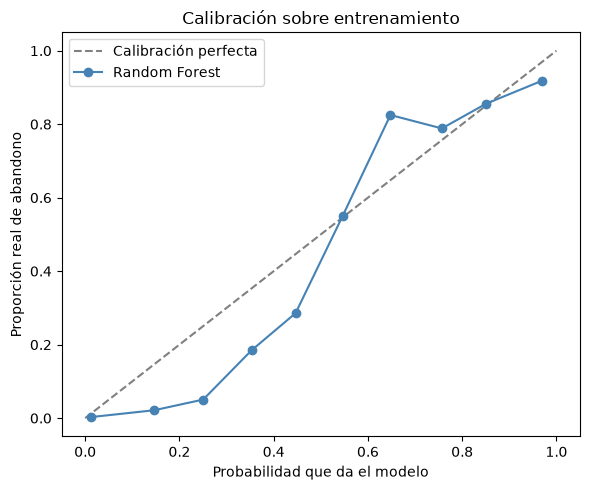

Puntaje de Brier: 0.0368


In [48]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

proporcion_real, probabilidad_media = calibration_curve(y_train, probabilidades, n_bins=10)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], "--", color="gray", label="Calibración perfecta")
ax.plot(probabilidad_media, proporcion_real, "o-", color="steelblue", label="Random Forest")
ax.set_xlabel("Probabilidad que da el modelo")
ax.set_ylabel("Proporción real de abandono")
ax.set_title("Calibración sobre entrenamiento")
ax.legend()
plt.tight_layout()
plt.show()

print("Puntaje de Brier:", round(brier_score_loss(y_train, probabilidades), 4))


El puntaje de Brier es 0,0368 y la curva se queda por debajo de la diagonal en casi todos los tramos: donde el modelo dice 0,4, abandona bastante menos del 40 %. Es la misma exageración que se veía en el promedio.

Para ordenar la lista de contactos esto no estorba, porque el orden entre clientes no cambia. Estorba si queremos decirle al equipo de retención que un cliente tiene 70 % de probabilidad de irse y que esa cifra signifique algo.

### 10.3. Calibración sigmoide

CalibratedClassifierCV aprende una función que corrige las probabilidades del modelo, ajustándola también por particiones para no usar los mismos datos con los que se entrenó. Volvemos a sacar probabilidades fuera de pliegue, ahora del modelo calibrado, y comparamos los dos puntajes de Brier.

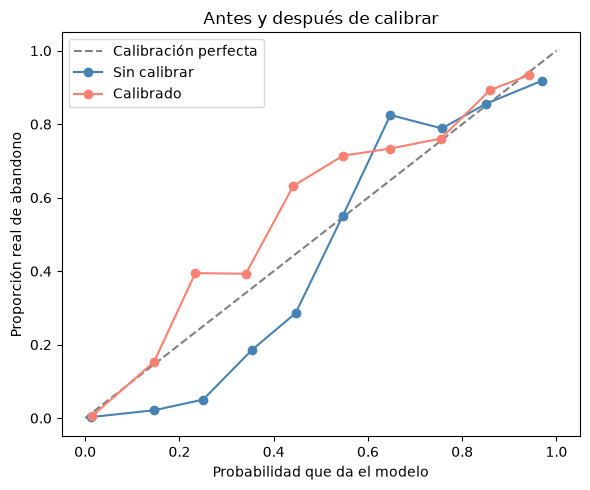

Brier sin calibrar: 0.0368
Brier calibrado:   0.0336
Nos quedamos con las probabilidades calibradas: True


In [49]:
from sklearn.calibration import CalibratedClassifierCV

modelo_calibrado = CalibratedClassifierCV(modelo_elegido, method="sigmoid", cv=5)

probabilidades_calibradas = cross_val_predict(
    modelo_calibrado, X_train, y_train, cv=particiones, method="predict_proba", n_jobs=-1
)[:, 1]

proporcion_cal, probabilidad_cal = calibration_curve(y_train, probabilidades_calibradas, n_bins=10)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], "--", color="gray", label="Calibración perfecta")
ax.plot(probabilidad_media, proporcion_real, "o-", color="steelblue", label="Sin calibrar")
ax.plot(probabilidad_cal, proporcion_cal, "o-", color="salmon", label="Calibrado")
ax.set_xlabel("Probabilidad que da el modelo")
ax.set_ylabel("Proporción real de abandono")
ax.set_title("Antes y después de calibrar")
ax.legend()
plt.tight_layout()
plt.show()

print("Brier sin calibrar:", round(brier_score_loss(y_train, probabilidades), 4))
print("Brier calibrado:  ", round(brier_score_loss(y_train, probabilidades_calibradas), 4))

brier_sin = brier_score_loss(y_train, probabilidades)
brier_con = brier_score_loss(y_train, probabilidades_calibradas)

if brier_con < brier_sin:
    probabilidades_elegidas = probabilidades_calibradas
    usamos_calibracion = True
else:
    probabilidades_elegidas = probabilidades
    usamos_calibracion = False

print("Nos quedamos con las probabilidades calibradas:", usamos_calibracion)


El Brier baja de 0,0368 a 0,0336 y la curva se acerca a la diagonal, así que seguimos con las probabilidades calibradas.

La mejora es modesta porque Random Forest ya ordenaba bien a los clientes. Lo que corrige la calibración es sobre todo el sesgo hacia arriba que mete el peso por clase.

### 10.4. El umbral

Recorremos los umbrales de 0,05 a 0,95 y miramos qué F1, precisión y recall da cada uno sobre las probabilidades fuera de pliegue. Bajar el umbral avisa de más clientes, así que sube el recall y baja la precisión; subirlo hace lo contrario.

In [50]:
rows = []
umbral = 0.05

while umbral <= 0.95:
    predicciones = (probabilidades_elegidas >= umbral).astype(int)
    rows.append({
        "Umbral": round(umbral, 2),
        "F1": round(f1_score(y_train, predicciones, zero_division=0), 4),
        "Precisión": round(precision_score(y_train, predicciones, zero_division=0), 4),
        "Recall": round(recall_score(y_train, predicciones, zero_division=0), 4),
        "Alertas": int(predicciones.sum())
    })
    umbral = umbral + 0.05

tabla_umbrales = pd.DataFrame(rows)
tabla_umbrales


,Umbral,F1,Precisión,Recall,Alertas
0,0.05,0.7524,0.6097,0.9823,638
1,0.10,0.8196,0.7098,0.9697,541
2,0.15,0.8473,0.7585,0.9596,501
3,0.20,0.8624,0.7953,0.9419,469
4,0.25,0.8647,0.8223,0.9116,439
5,0.30,0.8658,0.8306,0.9040,431
6,0.35,0.8727,0.8547,0.8914,413
7,0.40,0.8686,0.8610,0.8763,403
8,0.45,0.8579,0.8622,0.8535,392
9,0.50,0.8590,0.8724,0.8460,384


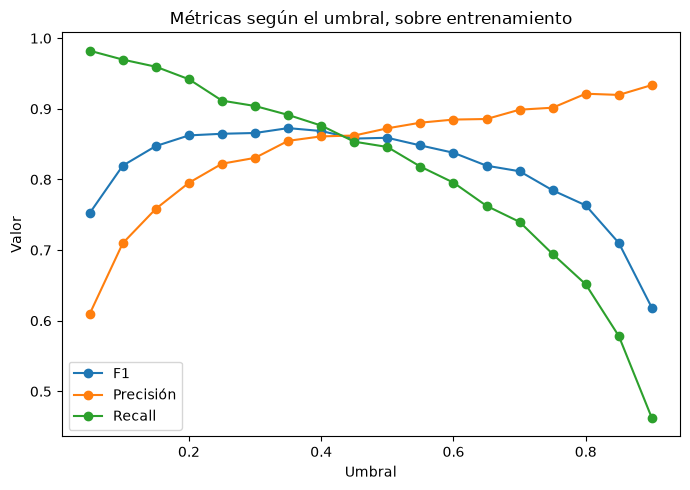

In [51]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(tabla_umbrales["Umbral"], tabla_umbrales["F1"], "o-", label="F1")
ax.plot(tabla_umbrales["Umbral"], tabla_umbrales["Precisión"], "o-", label="Precisión")
ax.plot(tabla_umbrales["Umbral"], tabla_umbrales["Recall"], "o-", label="Recall")
ax.set_xlabel("Umbral")
ax.set_ylabel("Valor")
ax.set_title("Métricas según el umbral, sobre entrenamiento")
ax.legend()
plt.tight_layout()
plt.show()


El F1 más alto está en el umbral 0,35, con 0,8727. La curva es bastante plana entre 0,25 y 0,40, todos por encima de 0,86, así que moverse dentro de ese rango cambia poco.

El intercambio se ve con claridad en los extremos. Con umbral 0,05 el recall es 0,9823 pero la precisión 0,6097: de 638 alertas, casi la mitad serían clientes que no pensaban irse. Con 0,90 la precisión sube a 0,9337 y el recall cae a 0,4621: se escaparía más de la mitad de los que sí se van.

### 10.5. Lo que queda decidido

Guardamos el umbral de mayor F1 y lo comparamos con el 0,5 por defecto.

In [52]:
fila_umbral = tabla_umbrales.sort_values("F1", ascending=False).iloc[0]
umbral_elegido = fila_umbral["Umbral"]

f1_por_defecto = tabla_umbrales[tabla_umbrales["Umbral"] == 0.5].iloc[0]["F1"]

print("Umbral elegido:", umbral_elegido)
print("F1 con ese umbral:", fila_umbral["F1"], "| con 0,5:", f1_por_defecto)
print("Precisión:", fila_umbral["Precisión"], "| Recall:", fila_umbral["Recall"])
print("Clientes que alertaría de los 2.520:", int(fila_umbral["Alertas"]))


Umbral elegido: 0.35
F1 con ese umbral: 0.8727 | con 0,5: 0.859
Precisión: 0.8547 | Recall: 0.8914
Clientes que alertaría de los 2.520: 413


Queda el umbral en 0,35. Frente al 0,5 por defecto, el F1 sube de 0,8590 a 0,8727, con un recall de 0,8914 y una precisión de 0,8547.

En términos del negocio, ese corte alerta sobre 413 de los 2.520 clientes de entrenamiento, el 16,4 %. Si el equipo de retención no tuviera capacidad para tantos contactos, el umbral es la perilla para ajustarlo: subirlo a 0,5 deja 384 alertas y a 0,7 deja 326, a cambio de dejar escapar más clientes.

[Volver al índice](#indice)

<a id="seccion-11"></a>
## 11. Evaluación final

Aquí abrimos los 630 clientes de prueba que reservamos en la sección 5 y que no han participado en ninguna decisión: ni en la exploración, ni en la comparación de modelos, ni en el ajuste, ni en la elección del umbral.

Esta medición se hace una sola vez. Si después de verla volviéramos a cambiar el modelo o el umbral, la prueba dejaría de ser independiente y el número perdería su sentido.

### 11.1. El modelo final

Entrenamos con todo el conjunto de entrenamiento, las 2.520 filas, el modelo que quedó elegido y con la calibración que decidimos en la sección 10.

In [53]:
modelo_final = CalibratedClassifierCV(modelo_elegido, method="sigmoid", cv=5)
modelo_final.fit(X_train, y_train)

print("Entrenado con", len(X_train), "clientes y", X_train.shape[1], "variables")
print("Umbral:", umbral_elegido)


Entrenado con 2520 clientes y 12 variables
Umbral: 0.35


### 11.2. Predicción sobre la prueba

Calculamos la probabilidad de abandono de cada uno de los 630 clientes y aplicamos el umbral.

In [54]:
probabilidades_test = modelo_final.predict_proba(X_test)[:, 1]
predicciones_test = (probabilidades_test >= umbral_elegido).astype(int)

print("Clientes de prueba:", len(y_test))
print("Abandonos reales:", int(y_test.sum()))
print("Clientes alertados por el modelo:", int(predicciones_test.sum()))


Clientes de prueba: 630
Abandonos reales: 99
Clientes alertados por el modelo: 107


### 11.3. Métricas

El F1 del abandono es la métrica principal. La precisión dice qué proporción de las alertas eran correctas y el recall qué proporción de los que se fueron alcanzamos a detectar. El ROC AUC y la precisión promedio no dependen del umbral: miden qué tan bien ordena el modelo a los clientes.

In [55]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import average_precision_score

rows = []
rows.append({
    "Métrica": "F1 del abandono",
    "Valor": round(f1_score(y_test, predicciones_test, zero_division=0), 4)
})
rows.append({
    "Métrica": "Precisión",
    "Valor": round(precision_score(y_test, predicciones_test, zero_division=0), 4)
})
rows.append({
    "Métrica": "Recall",
    "Valor": round(recall_score(y_test, predicciones_test, zero_division=0), 4)
})
rows.append({
    "Métrica": "Exactitud",
    "Valor": round(accuracy_score(y_test, predicciones_test), 4)
})
rows.append({
    "Métrica": "ROC AUC",
    "Valor": round(roc_auc_score(y_test, probabilidades_test), 4)
})
rows.append({
    "Métrica": "Precisión promedio",
    "Valor": round(average_precision_score(y_test, probabilidades_test), 4)
})
rows.append({
    "Métrica": "Brier",
    "Valor": round(brier_score_loss(y_test, probabilidades_test), 4)
})

tabla_test = pd.DataFrame(rows)
tabla_test


,Métrica,Valor
0,F1 del abandono,0.9029
1,Precisión,0.8692
2,Recall,0.9394
3,Exactitud,0.9683
4,ROC AUC,0.9861
5,Precisión promedio,0.9209
6,Brier,0.0278


F1 de 0,9029 sobre los 630 clientes reservados, con recall de 0,9394 y precisión de 0,8692. El ROC AUC de 0,9861 y la precisión promedio de 0,9209 dicen que el modelo ordena muy bien a los clientes, casi con independencia de dónde se ponga el corte.

El F1 de prueba queda por encima del 0,8727 que estimamos en validación, y conviene no leerlo como que el modelo resultó mejor de lo que creíamos. El modelo final se entrena con 2.520 filas en vez de las 2.268 de cada vuelta de la validación, y sobre todo, 630 clientes con 99 abandonos son pocos: esta cifra tiene su propio margen, de unas tres centésimas. Lo razonable es decir que las dos mediciones son consistentes y que el desempeño está entre 0,87 y 0,90.

La exactitud de 0,9683 es la métrica que decidimos no usar para decidir, y aquí se ve por qué: un modelo que respondiera siempre permanece sacaría 0,8429 sin detectar a nadie.

### 11.4. Matriz de confusión

Los cuatro casos posibles: clientes que se fueron y detectamos, los que se fueron y se nos escaparon, los que se quedaron y alertamos de más, y los que se quedaron y dejamos tranquilos.

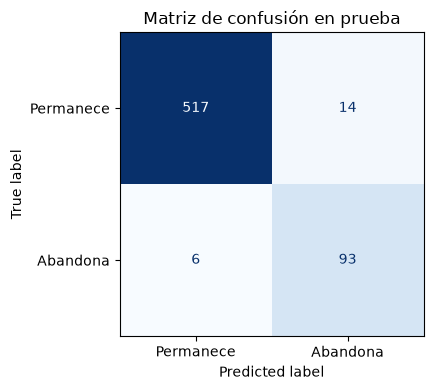

Abandonos detectados: 93 de 99
Abandonos no detectados: 6
Falsas alarmas: 14 de 531 clientes que permanecen


In [56]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

matriz = confusion_matrix(y_test, predicciones_test)

fig, ax = plt.subplots(figsize=(5, 4))
dibujo = ConfusionMatrixDisplay(confusion_matrix=matriz,
                                display_labels=["Permanece", "Abandona"])
dibujo.plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Matriz de confusión en prueba")
plt.tight_layout()
plt.show()

print("Abandonos detectados:", matriz[1][1], "de", matriz[1][0] + matriz[1][1])
print("Abandonos no detectados:", matriz[1][0])
print("Falsas alarmas:", matriz[0][1], "de", matriz[0][0] + matriz[0][1], "clientes que permanecen")


De los 99 clientes que abandonaron, el modelo detectó 93 y dejó escapar 6. De los 531 que permanecieron, alertó de más sobre 14.

Dicho en términos de la operación: la lista tendría 107 nombres, 93 de ellos clientes que de verdad se iban. El costo son 14 llamadas gastadas en gente que no pensaba irse, y el riesgo que queda son 6 clientes que se pierden sin aviso.

### 11.5. Curvas

La curva ROC muestra el intercambio entre detectar abandonos y alertar de más, para todos los umbrales posibles. La curva de precisión y recall dice lo mismo pero centrada en la clase minoritaria, que es la que nos interesa; la línea punteada marca el 15,7 % de abandono, que es lo que acertaría alertar al azar.

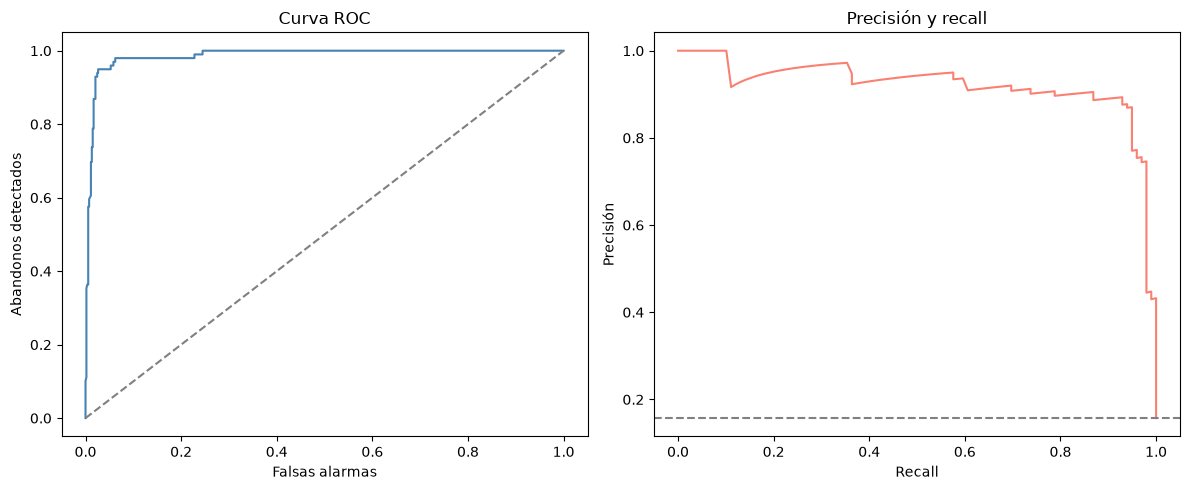

In [57]:
from sklearn.metrics import roc_curve
from sklearn.metrics import precision_recall_curve

falsos_positivos, verdaderos_positivos, umbrales_roc = roc_curve(y_test, probabilidades_test)
precisiones, recalls, umbrales_pr = precision_recall_curve(y_test, probabilidades_test)

fig, ejes = plt.subplots(1, 2, figsize=(12, 5))

ejes[0].plot(falsos_positivos, verdaderos_positivos, color="steelblue")
ejes[0].plot([0, 1], [0, 1], "--", color="gray")
ejes[0].set_xlabel("Falsas alarmas")
ejes[0].set_ylabel("Abandonos detectados")
ejes[0].set_title("Curva ROC")

ejes[1].plot(recalls, precisiones, color="salmon")
ejes[1].axhline(y_test.mean(), linestyle="--", color="gray")
ejes[1].set_xlabel("Recall")
ejes[1].set_ylabel("Precisión")
ejes[1].set_title("Precisión y recall")

plt.tight_layout()
plt.show()


### 11.6. La lista de prioridad

Así se usaría en la práctica: ordenamos a los clientes de prueba por probabilidad y miramos cuántos de los que de verdad abandonaron caen en los primeros puestos. Es la pregunta que le importa al equipo de retención, que solo puede llamar a unos cuantos.

In [58]:
priorizacion = pd.DataFrame({
    "probabilidad": probabilidades_test,
    "abandono_real": y_test.to_numpy()
})
priorizacion = priorizacion.sort_values("probabilidad", ascending=False).reset_index(drop=True)

rows = []

for cantidad in [25, 50, 100, 150]:
    primeros = priorizacion.head(cantidad)
    rows.append({
        "Clientes contactados": cantidad,
        "Abandonos dentro": int(primeros["abandono_real"].sum()),
        "Aciertos": round(primeros["abandono_real"].mean() * 100, 1),
        "De los 99 abandonos": round(primeros["abandono_real"].sum() / y_test.sum() * 100, 1)
    })

tabla_priorizacion = pd.DataFrame(rows)
tabla_priorizacion


,Clientes contactados,Abandonos dentro,Aciertos,De los 99 abandonos
0,25,24,96.0,24.2
1,50,47,94.0,47.5
2,100,89,89.0,89.9
3,150,97,64.7,98.0


Si el equipo solo pudiera contactar a 25 clientes, 24 de ellos serían abandonos reales. Con 50 llamadas, 47. Con 100 llegan a 89, que son nueve de cada diez de todos los abandonos del conjunto.

La tabla también muestra dónde deja de rendir el esfuerzo: pasar de 100 a 150 contactos solo agrega 8 abandonos más y la tasa de acierto cae del 89 % al 64,7 %. Las últimas cincuenta llamadas encuentran cada vez menos.

### Cierre de la sección

El modelo detecta 93 de los 99 clientes que abandonaron, con 14 falsas alarmas, y alcanza un F1 de 0,9029 sobre clientes que nunca vio.

Lo que este número no dice. Es una sola medición sobre 630 clientes, así que tiene un margen de unas tres centésimas y no conviene reportarlo como cifra exacta. El conjunto no trae fechas ni un identificador de cliente, de modo que no se puede afirmar nada sobre cómo le iría en otro periodo o en otro mercado. Y una de las variables más fuertes, el estado de la línea, es un indicador tardío: avisa cuando el cliente ya dejó de usar el servicio, que es cuando queda menos margen para retenerlo.

La prueba ya está usada. A partir de aquí no se cambia el modelo ni el umbral; lo que sigue es guardarlo.

[Volver al índice](#indice)

<a id="seccion-12"></a>
## 12. Despliegue y conclusiones

Guardamos el modelo para poder usarlo sin volver a entrenarlo, comprobamos que al recargarlo predice exactamente lo mismo, y cerramos con lo que aprendimos.

### 12.1. Qué variables pesan

Random Forest permite ver cuánto usó cada variable para separar a los clientes. No dice si empuja hacia el abandono o en contra, solo cuánto se apoyó en ella, pero sirve para explicarle al equipo de retención en qué se está fijando el modelo.

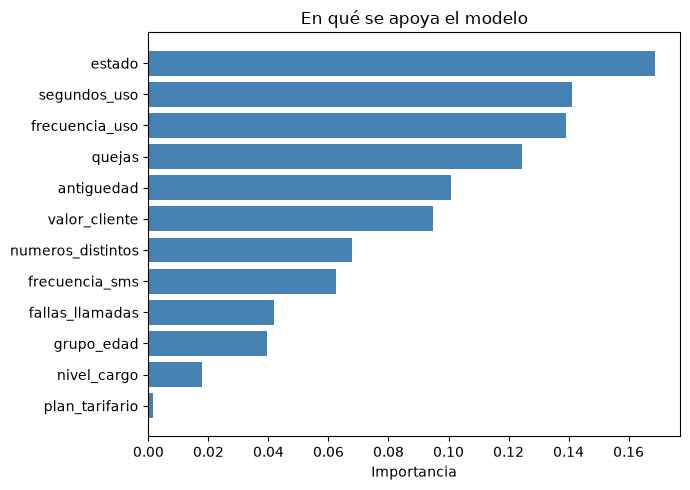

,Variable,Importancia
10,estado,0.1687
4,segundos_uso,0.1411
5,frecuencia_uso,0.1392
1,quejas,0.1244
2,antiguedad,0.1007
11,valor_cliente,0.0949
7,numeros_distintos,0.0677
6,frecuencia_sms,0.0626
0,fallas_llamadas,0.0420
8,grupo_edad,0.0395


In [59]:
importancias = modelo_elegido.named_steps["modelo"].feature_importances_

tabla_importancias = pd.DataFrame({
    "Variable": X_train.columns,
    "Importancia": importancias.round(4)
})
tabla_importancias = tabla_importancias.sort_values("Importancia", ascending=False)

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(tabla_importancias["Variable"], tabla_importancias["Importancia"], color="steelblue")
ax.invert_yaxis()
ax.set_xlabel("Importancia")
ax.set_title("En qué se apoya el modelo")
plt.tight_layout()
plt.show()

tabla_importancias


El estado de la línea encabeza con 0,1687, seguido del bloque de uso, segundos con 0,1411 y frecuencia con 0,1392, y después las quejas con 0,1244.

Hay dos cosas que no coinciden con lo que vimos en la exploración. Las quejas eran la señal más fuerte por phik y por ANOVA, y aquí quedan cuartas: es una variable binaria que solo afecta al 8 % de los clientes, así que el modelo la usa en pocos cortes, aunque sean muy decisivos. Y la antigüedad, que por ANOVA casi no distinguía, aparece quinta con 0,1007, porque el bosque la aprovecha combinada con las demás. Es otra forma de ver lo que ya nos había mostrado la selección de variables.

Al final quedan nivel_cargo con 0,0177 y plan_tarifario con 0,0015, que el modelo prácticamente no usa.

### 12.2. Guardar el modelo

Guardamos tres cosas en un solo archivo: el modelo ya entrenado y calibrado, el umbral y los nombres de las columnas en el orden en que las espera. Aparte va un archivo de metadatos con las decisiones y los resultados, para que quien use el modelo sepa de dónde salió.

El archivo reemplaza al modelo anterior de once entradas, que queda en el historial del repositorio.

In [60]:
import joblib
import json
import datetime
import sklearn
import imblearn

RUTA_MODELOS = RUTA_BASE + "models/"

artefacto = {
    "modelo": modelo_final,
    "umbral": float(umbral_elegido),
    "columnas_entrada": list(X_train.columns)
}

joblib.dump(artefacto, RUTA_MODELOS + "modelo_final.joblib")

metricas_test = {}
for i in range(len(tabla_test)):
    fila = tabla_test.iloc[i]
    metricas_test[fila["Métrica"]] = float(fila["Valor"])

metadata = {
    "modelo": nombre_elegido,
    "hiperparametros": parametros_elegidos,
    "estrategia_balanceo": "peso por clase",
    "calibracion": "sigmoide sobre el modelo completo",
    "umbral": float(umbral_elegido),
    "columnas_entrada": list(X_train.columns),
    "f1_validacion": float(elegido["F1"]),
    "metricas_test": metricas_test,
    "procedimiento": ("Partición 80/20 estratificada; exploración, comparación de 41 combinaciones, "
                      "ajuste, calibración y umbral decididos solo con entrenamiento; prueba "
                      "consultada una vez al final."),
    "advertencia": ("El F1 de prueba proviene de 630 clientes con 99 abandonos y tiene un margen de "
                    "unas tres centésimas; reportar el desempeño como un rango."),
    "fecha_entrenamiento": datetime.datetime.now().isoformat(timespec="seconds"),
    "version_sklearn": sklearn.__version__,
    "version_imblearn": imblearn.__version__
}

with open(RUTA_MODELOS + "metadata_modelo.json", "w", encoding="utf-8") as archivo:
    json.dump(metadata, archivo, ensure_ascii=False, indent=2)

print("Guardados modelo_final.joblib y metadata_modelo.json en", RUTA_MODELOS)


Guardados modelo_final.joblib y metadata_modelo.json en ./models/


### 12.3. Datos y priorización

Guardamos también los dos conjuntos con las doce entradas, para no tener que repetir la partición cada vez que se necesiten, y una tabla de priorización que responde qué pasa si solo se contacta a los clientes de mayor riesgo.

In [61]:
RUTA_DATOS_SALIDA = RUTA_BASE + "data/"
RUTA_RESULTADOS = RUTA_BASE + "resultados/"

train.to_csv(RUTA_DATOS_SALIDA + "train.csv", index=False)
test.to_csv(RUTA_DATOS_SALIDA + "test.csv", index=False)

rows = []
tasa_base = y_test.mean()

for fraccion in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]:
    cantidad = int(round(len(priorizacion) * fraccion))
    primeros = priorizacion.head(cantidad)
    aciertos = primeros["abandono_real"].mean()
    rows.append({
        "Fraccion_contactada": fraccion,
        "Clientes": cantidad,
        "Precision": round(aciertos, 4),
        "Recall": round(primeros["abandono_real"].sum() / y_test.sum(), 4),
        "Lift": round(aciertos / tasa_base, 2)
    })

tabla_app = pd.DataFrame(rows)
tabla_app.to_csv(RUTA_RESULTADOS + "priorizacion_test.csv", index=False)

print("Guardados train.csv y test.csv en", RUTA_DATOS_SALIDA)
print("Guardada priorizacion_test.csv en", RUTA_RESULTADOS)

tabla_app


Guardados train.csv y test.csv en ./data/
Guardada priorizacion_test.csv en ./resultados/


,Fraccion_contactada,Clientes,Precision,Recall,Lift
0,0.05,32,0.9688,0.3131,6.16
1,0.10,63,0.9365,0.5960,5.96
2,0.15,94,0.9043,0.8586,5.75
3,0.20,126,0.7540,0.9596,4.80
4,0.25,158,0.6139,0.9798,3.91
5,0.30,189,0.5132,0.9798,3.27


Los dos conjuntos quedan guardados con las doce entradas más abandono: 2.520 filas de entrenamiento y 630 de prueba, con la misma partición que usamos en todo el cuaderno.

La tabla de priorización responde la pregunta del equipo de retención. Contactando al 15 % de los clientes, 94 personas, se alcanza al 85,9 % de los que abandonan y acierta el 90,4 % de las llamadas: 5,75 veces lo que daría llamar al azar. A partir del 20 % el rendimiento cae, porque se capturan nueve de cada diez abandonos pero ya solo tres de cada cuatro llamadas aciertan.

### 12.4. Comprobación de la recarga

Cargamos lo que acabamos de guardar y volvemos a predecir sobre la prueba. Las probabilidades deben ser idénticas, no parecidas: si no lo son, el archivo guardado no reproduce el modelo que medimos.

In [62]:
artefacto_recargado = joblib.load(RUTA_MODELOS + "modelo_final.joblib")

modelo_recargado = artefacto_recargado["modelo"]
umbral_recargado = artefacto_recargado["umbral"]
columnas_recargadas = artefacto_recargado["columnas_entrada"]

probabilidades_recargadas = modelo_recargado.predict_proba(X_test[columnas_recargadas])[:, 1]
predicciones_recargadas = (probabilidades_recargadas >= umbral_recargado).astype(int)

print("Probabilidades idénticas:", (probabilidades_recargadas == probabilidades_test).all())
print("Predicciones idénticas:", (predicciones_recargadas == predicciones_test).all())
print("Umbral recargado:", umbral_recargado)
print("Columnas recargadas:", len(columnas_recargadas))


Probabilidades idénticas: True
Predicciones idénticas: True
Umbral recargado: 0.35
Columnas recargadas: 12


Las probabilidades y las predicciones recargadas son idénticas a las de la sección 11, con el mismo umbral y las doce columnas en el mismo orden. El archivo reproduce el modelo.

## Conclusiones

El objetivo era entregarle al equipo de retención una lista corta de clientes en riesgo, ordenada por prioridad. El modelo final detecta 93 de los 99 clientes que abandonaron en el conjunto de prueba, a cambio de 14 llamadas a clientes que no pensaban irse, con un F1 de 0,9029.

Más útil que esa cifra es la lista: contactando a los cien clientes con mayor probabilidad se alcanza a nueve de cada diez de los que se van. Contactar a cincuenta más solo agrega ocho.

Sobre los datos. Partimos de trece entradas y quitamos solo edad, por ser idéntica a grupo_edad. Conservamos estado y valor_cliente después de comprobar que aportan: el primero separa por su cuenta y el segundo, aunque es una combinación de las demás, no introduce información de fuera del periodo medido. Las filas repetidas se conservaron tratando cada una como un cliente distinto, porque el archivo no trae identificador.

Sobre el modelo. De 41 combinaciones de modelo y balanceo salieron tres candidatos muy parejos, y entre ellos elegimos Random Forest por ser el más simple y rápido ante un empate dentro del error estándar. Los modelos de árbol superaron con claridad a los lineales, y el balanceo ayudó bastante menos que la elección del modelo. Quitar variables con ANOVA empeoró a los tres candidatos, así que se conservaron las doce.

Sobre la medición. Todas las decisiones se tomaron con entrenamiento y la prueba se consultó una sola vez al final. El F1 de validación fue 0,8722 y el de prueba 0,9029; la diferencia cabe en el margen de una muestra de 630 clientes, así que lo correcto es reportar el desempeño como un rango entre 0,87 y 0,90, no como una cifra exacta.

Limitaciones. El conjunto no trae fechas ni identificador de cliente, de modo que no podemos comprobar el orden de los hechos cliente por cliente ni decir cómo le iría al modelo en otro periodo o en otro mercado. La variable más fuerte, el estado de la línea, es un indicador tardío: avisa cuando el cliente ya dejó de usar el servicio, que es cuando queda menos margen para retenerlo. Y el modelo aprendió de una sola empresa de telecomunicaciones iraní; trasladarlo a otro contexto exigiría volver a entrenarlo.

[Volver al índice](#indice)